# 03 · Anomalies, accounts and party details
**Owner:** Chew Jia Yi · **Needs:** run `04_integration_validation.ipynb` first. It builds the shared data, including this notebook's derived columns (`rid`, `ts`, `cross_border`, `o_det_cc`, `b_det_cc`, `o_det_acct`, `b_det_acct`, `b_party_text`).

**How to run**
1. Run notebook 04 once (it loads the CSV, adds the derived columns and runs QC for the whole team).
2. Run this notebook top to bottom. Tables are saved to `outputs/tables/` and charts to `outputs/figures/`.
3. If you hit *Out of Memory*, set the environment variables `SWIFT_MEMORY=4GB` and `SWIFT_THREADS=4` before starting Jupyter, restart the kernel and run again. Helper tables live in an on-disk database, so they don't fill RAM.

**Rules of this notebook**
- Full data is used everywhere (anomalies are rare, so sampling would leave too few rows). The only exception is control samples, which are marked as such.
- Nothing is deleted. Anomalies and outliers are kept and flagged.
- All times are UTC.
- Hypothesis IDs (A1…, AC1…, D1…) match `outputs/tables/hypotheses_03.csv`. After each section, update that file with ✅ held / ❌ rejected / ⚠️ partial.

### Evidence policy (updated 18 Nov 2026)
- **One verdict system, two kinds of rule** (column `verdict_basis` in `evidence_matrix.csv`):
  - *Accuracy rules* state a deterministic prediction (e.g. "Direct ⇔ 2 banks"). They are graded by the share of tested rows that obey them: `Confirmed` ≥ 99% · `Strong` 95–99% · `Partial` 70–95% · `Weak` below that. The tested denominator and any exclusions are always shown.
  - *Effect rules* state a size, an independence or a distribution (e.g. "×7.4 per business party").
    - `Supported`: the stated effect holds **and** the out-of-sample (holdout) estimate agrees with it, by the criterion written in `holdout_rule`, e.g. overlapping 95% CIs.
    - `Approximate`: the direction is right, but the holdout disagrees, is missing, or the model misses. The reason is in `verdict_note`.
    - `Rejected` or `Inconclusive` otherwise.
- **Causal status** says how far the evidence goes. It describes the evidence, not proof of the generator's code.
  - `Mechanism`: needs a 95% CI, an out-of-sample check, a subgroup check and a practical meaning. Rules lacking any of these are automatically downgraded.
  - `Association`: a real, stable pattern whose cause is not identified.
  - `Structural`: true by how the fields are defined.
  - `Rejected`: the stated prediction fails.
  - `Unresolved`: the tested method found no support but cannot rule the mechanism out.
- **Interpretations** ("consistent with …", "plausibly …") are possible explanations, not proven causes. "No measurable association" is not proof of independence, and "no detectable difference" is not proof that something is random.
- **Local time** uses clock offsets inferred from the CSV under stated assumptions (Monday–Friday week, no summer time, one offset per country). They are not verified time zones, and office-hour results on that clock are partly built into the offsets.
- **READY** (end of notebook 04) means every file comes from the current code and data, and every required piece of evidence is present and consistent. It does not prove that a rule is the generator's actual code.
- **Accounts** are always identified by **(BIC8, account number)**, because 2.4% of receiver account numbers recur at several banks.
- **Data used:** only the organiser CSV. Local currency and each country's clock offset are **inferred from the CSV itself**; the clock offsets come from the training period only. No time-zone database, currency table or GDP data enters any calculation.
- Saved outputs are cleared in this pack. Re-run in the order 04 → 01 → 02 → 03 → 04 before quoting any number.

## 0. Setup (shared with all notebooks)

In [1]:
from pathlib import Path
import os, warnings; warnings.filterwarnings('ignore')
import duckdb, numpy as np, pandas as pd
import matplotlib.pyplot as plt
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 60)

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
RAW, PROC = ROOT / 'data' / 'raw', ROOT / 'data' / 'processed'
FIG, TAB = ROOT / 'outputs' / 'figures', ROOT / 'outputs' / 'tables'
RULES = TAB / 'rules'                       # one rules file per notebook -> combined into outputs/tables/rules_log.csv
for d in (RAW, PROC, FIG, TAB, RULES): d.mkdir(parents=True, exist_ok=True)
FULL    = PROC / 'payments_clean.parquet'   # all 10M rows (nothing removed) + derived columns, built by notebook 04
SAMPLE  = PROC / 'sample_20pct.parquet'     # 20% Bernoulli sample (seed 42), no free-text columns, still includes anomalies
ANOM    = PROC / 'anomalies.parquet'        # every labelled anomaly row, all columns
SCHEMA_VERSION = '2'                        # bump when derived columns change -> notebook 04 rebuilds the files

def connect(db=':memory:'):
    con = duckdb.connect(str(db))
    con.execute("SET TimeZone='UTC'")       # never skip: otherwise DuckDB shows laptop time (+08)
    con.execute("SET preserve_insertion_order=false")
    try: con.execute("SET enable_progress_bar=false")   # no progress widgets saved in the notebook ("Could not render ... widget" in viewers)
    except Exception: pass                           # (older setups without ipywidgets show no widget anyway)
    con.execute(f"SET temp_directory='{(PROC / 'duck_tmp').as_posix()}'")   # big joins spill to disk instead of crashing
    if os.environ.get('SWIFT_MEMORY'):  con.execute(f"SET memory_limit='{os.environ['SWIFT_MEMORY']}'")   # e.g. 4GB on an 8 GB laptop
    if os.environ.get('SWIFT_THREADS'): con.execute(f"SET threads={int(os.environ['SWIFT_THREADS'])}")
    return con

In [2]:
con = connect(PROC / 'work_03.duckdb')      # on-disk database: helper tables (pairseq, acct_long2, ...) live on disk, not in RAM

In [3]:
def sql(q):
    """Run SQL on the full data and return a pandas DataFrame."""
    return con.execute(q).df()
q = sql
def save_table(df, name):
    """Save a result table to outputs/tables/<name>.csv and return it for display."""
    df.to_csv(TAB / f'{name}.csv', index=False); return df

RULE_COLS = ['id', 'group', 'rule', 'test', 'value', 'verdict', 'evidence_files', 'interpretation']
VERDICTS = 'Confirmed (holds in >=99% of rows / effect matches) · Strong (95-99%) · Partial (70-95% or only in a subgroup) · Weak (<70%) · Rejected (prediction fails)'
def verdict_from_share(x):
    return 'Confirmed' if x >= 0.99 else 'Strong' if x >= 0.95 else 'Partial' if x >= 0.70 else 'Weak'

def combine_rules():
    """Combine standardized teammate rule tables and flag unfinished placeholders.

    Running notebook 04 *first* creates its core rules; re-run the final
    consolidation cell after notebooks 01-03 to capture every teammate's work.
    """
    frames = []
    for f in sorted(RULES.glob('rules_*.csv')):
        d = pd.read_csv(f)
        aliases = {'observed_evidence_table_or_chart': 'evidence_files',
                   'interpretation_real_world': 'interpretation', 'confidence': 'verdict'}
        d = d.rename(columns={a:b for a,b in aliases.items() if a in d and b not in d})
        if 'rule' not in d and {'when_condition', 'then_effect'} <= set(d.columns):
            d['rule'] = d['when_condition'].fillna('') + ' -> ' + d['then_effect'].fillna('')
        if 'value' not in d and 'size' in d: d['value'] = d['size']
        for col in RULE_COLS:
            if col not in d: d[col] = ''
        d['source'] = f.name
        frames.append(d)
    out = pd.concat(frames, ignore_index=True) if frames else pd.DataFrame(columns=RULE_COLS+['source'])
    required = {'rules_04_core.csv','rules_02.csv','rules_03_anomalies.csv'}
    missing = sorted(required - {f.name for f in RULES.glob('rules_*.csv')})
    dup = out['id'].astype(str).duplicated(keep=False) if len(out) else []
    unfinished = out.astype(str).apply(lambda col: col.str.contains(r'TODO|\?\?|A2-example', case=False, regex=True)).any(axis=1) if len(out) else []
    if missing: print('INTEGRATION INCOMPLETE — missing:', ', '.join(missing))
    if len(out) and any(dup): print('INTEGRATION WARNING — repeated rule IDs:', out.loc[dup,'id'].tolist())
    if len(out) and any(unfinished): print('INTEGRATION WARNING — unresolved template cells:', out.loc[unfinished,'id'].tolist())
    out = out[ RULE_COLS + ['source'] + [c for c in out if c not in RULE_COLS + ['source']] ]
    out.to_csv(TAB/'rules_log.csv', index=False)
    return out

In [4]:
from scipy.stats import chi2_contingency
save = save_table                            # this notebook's name for "save a table to outputs/tables"
pd.set_option('display.float_format', '{:,.4f}'.format)
APPENDIX_LABELS = ['ROMANCE_SCAM', 'CEO_SCAM', 'ACCOUNT_REPLACEMENT_SCAM', 'FAT_FINGER_MISTAKE', 'DUPLICATE_PAYMENT']
APPX_SQL = ', '.join(f"'{a}'" for a in APPENDIX_LABELS)
print('DuckDB', duckdb.__version__)

DuckDB 2.0.0


In [5]:
# Main view `p` = full data with the shared derived columns (see notebook 04, section 1)
assert FULL.exists() and (PROC / '_schema_version.txt').exists() and (PROC / '_schema_version.txt').read_text().strip() == SCHEMA_VERSION, \
    'Shared data missing or outdated: run notebooks/04_integration_validation.ipynb first'
con.execute(f"CREATE OR REPLACE VIEW p AS SELECT * FROM read_parquet('{FULL.as_posix()}')")
# Local currency of each BIC country = the currency its senders use most (inferred from this dataset, no external lookup)
con.execute("""CREATE OR REPLACE TABLE local_ccy AS
  SELECT o_cc AS cc, arg_max(CURRENCY_CODE, n) AS local_ccy FROM
  (SELECT o_cc, CURRENCY_CODE, count(*) n FROM p GROUP BY ALL) GROUP BY o_cc""")
print(f"{con.execute('SELECT count(*) FROM p').fetchone()[0]:,} payments loaded")

10,000,000 payments loaded


In [6]:
# Evidence toolkit (identical in every notebook): 95% CIs, tests, a time-based train/test split and causal labels
from scipy import stats
EVID_COLS = ['id', 'statistic_ci', 'p_value', 'out_of_sample', 'invariance', 'causal_status', 'practical_significance',
             'holdout_agrees', 'holdout_rule']   # holdout_agrees: does the out-of-sample estimate agree with the stated effect / CI?
CAUSAL = {   # how strongly a rule is a cause-and-effect rule of the generator (used in every evidence_*.csv)
    'Mechanism':   'consistent with a generator rule: holds after controls, out of sample and in every subgroup tested, and a placebo / '
                   'negative control shows no effect (supported by the data, not proof of the generator code)',
    'Structural':  'true by how the fields are built (a definition or an accounting identity), not a behavioural finding',
    'Association': 'real and stable pattern, but the data cannot show why: an unobserved cause is possible',
    'Rejected':    'the stated prediction fails, or the pattern is explained away by a confounder',
    'Unresolved':  'the tested method found no support, but it cannot rule the mechanism out (e.g. matching may miss links)'}
# A rule may be called 'Mechanism' only with ALL of these filled in; notebook 04 downgrades it to 'Association' otherwise
MECHANISM_NEEDS = ['statistic_ci', 'out_of_sample', 'invariance', 'practical_significance']

def wilson(k, n, z=1.96):
    """95% Wilson score interval for a share k/n (stays inside 0-100%, works for 0% and 100%)."""
    if not n: return np.nan, np.nan
    p = k / n; d = 1 + z * z / n; c = (p + z * z / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return max(0.0, c - h), min(1.0, c + h)

def share_ci(k, n, digits=2):
    """'97.80% [97.78%, 97.82%], n = 1,234' for a share k/n."""
    if not n: return 'n = 0'
    lo, hi = wilson(k, n); f = f'{{:.{digits}%}}'
    return f'{f.format(k / n)} [{f.format(lo)}, {f.format(hi)}], n = {int(n):,}'

def two_prop(k1, n1, k2, n2):
    """Share difference (group 1 - group 2), its 95% CI and a two-sided z-test p-value."""
    if not n1 or not n2: return np.nan, (np.nan, np.nan), np.nan
    p1, p2 = k1 / n1, k2 / n2; pp = (k1 + k2) / (n1 + n2)
    se0 = np.sqrt(pp * (1 - pp) * (1 / n1 + 1 / n2)); se = np.sqrt(p1 * (1 - p1) / n1 + p2 * (1 - p2) / n2)
    pval = 2 * stats.norm.sf(abs(p1 - p2) / se0) if se0 > 0 else (0.0 if p1 != p2 else 1.0)
    return p1 - p2, (p1 - p2 - 1.96 * se, p1 - p2 + 1.96 * se), pval

def paired_prop(a, b):
    """Two yes/no outcomes measured on the SAME rows (e.g. office hour on local clock vs UTC): McNemar test.
    Returns share(a) - share(b), its 95% CI and the p-value; only the discordant rows carry information."""
    a, b = np.asarray(a, bool), np.asarray(b, bool); n = len(a)
    n10, n01 = int((a & ~b).sum()), int((~a & b).sum()); d = (n10 - n01) / n
    se = np.sqrt(max(n10 + n01 - (n10 - n01) ** 2 / n, 0)) / n
    pval = stats.binomtest(n10, n10 + n01).pvalue if 0 < n10 + n01 < 1000 else (2 * stats.norm.sf(abs(n10 - n01) / np.sqrt(n10 + n01)) if n10 + n01 else 1.0)
    return d, (d - 1.96 * se, d + 1.96 * se), pval

def cramers_v_ct(ct):
    ct = np.asarray(ct, float); chi2 = stats.chi2_contingency(ct)[0]
    return np.sqrt(chi2 / (ct.sum() * (min(ct.shape) - 1)))

def v_ci(ct, reps=200, seed=0):
    """Cramér's V with a 95% CI (multinomial bootstrap of the contingency table)."""
    ct = np.asarray(ct, float); rng = np.random.default_rng(seed); n = int(ct.sum())
    boot = [cramers_v_ct(rng.multinomial(n, (ct / n).ravel()).reshape(ct.shape) + 1e-9) for _ in range(reps)]
    return cramers_v_ct(ct), np.percentile(boot, [2.5, 97.5])

def fmt_p(p):
    if p is None or not np.isfinite(p): return 'p = n/a'
    return 'p < 1e-300' if p == 0 else f'p = {p:.1e}' if p < 1e-3 else f'p = {p:.3f}'

def median_ci(x):
    """Distribution-free 95% CI of a median from order statistics (no bootstrap needed)."""
    x = np.sort(np.asarray(x)); n = len(x)
    if n == 0: return np.nan, np.nan
    h = 1.96 * np.sqrt(n) / 2
    return x[max(0, int(np.floor(n / 2 - h)))], x[min(n - 1, int(np.ceil(n / 2 + h)))]

# Out-of-sample check by TIME: a rule is fitted on the first 2/3 of the data window and re-tested on the last 1/3
T_SPLIT = int(con.execute("SELECT quantile_disc(EPOCH_SECONDS, 2/3) FROM p").fetchall()[0][0])
print('train = before', pd.to_datetime(T_SPLIT, unit='s'), 'UTC; test = after')

import hashlib, json as _json
def code_hash(prefix):
    """Fingerprint of a notebook's CODE cells as saved on disk (outputs ignored): proves which code version made a file."""
    f = sorted((ROOT / 'notebooks').glob(f'{prefix}_*.ipynb'))
    if not f: return ''
    cells = _json.loads(f[0].read_text(encoding='utf-8'))['cells']
    return hashlib.sha1('\n'.join(''.join(c['source']) for c in cells if c['cell_type'] == 'code').encode()).hexdigest()[:12]
DATA_STAMP = f"{FULL.stat().st_size}-{int(FULL.stat().st_mtime)}"      # identifies the data build the results came from

def overlap(a, b):
    """True if two intervals (lo, hi) overlap: used to say a holdout estimate agrees with the full-data estimate."""
    return bool(max(a[0], b[0]) <= min(a[1], b[1]))
def holdout(ok, rule):
    return dict(holdout_agrees=bool(ok), holdout_rule=rule)

def save_evidence(rows, name):
    """rows: dicts with EVID_COLS -> outputs/tables/rules/evidence_<name>.csv (merged into the evidence matrix by notebook 04).
    Each file also records the code version (code_hash) and the data build (data_stamp) it came from."""
    e = pd.DataFrame(rows).reindex(columns=EVID_COLS)
    e['code_hash'], e['data_stamp'] = code_hash(name), DATA_STAMP
    bad = set(e.causal_status.dropna()) - set(CAUSAL)
    assert not bad, f'unknown causal_status {bad}'
    e.to_csv(RULES / f'evidence_{name}.csv', index=False); return e

train = before 2023-06-28 12:22:04 UTC; test = after


## 1–2. Load and quality control
These are now in **notebook 04** (one shared load and one QC issues log for the team: `outputs/tables/qc_issues_log.csv`). The quick check below confirms the shared data has the columns this notebook needs.

In [7]:
need = {'rid', 'ts', 'cross_border', 'o_det_cc', 'b_det_cc', 'o_det_acct', 'b_det_acct', 'b_party_text'}
missing = need - set(sql('DESCRIBE p').column_name)
assert not missing, f'Shared data is missing {missing}: re-run notebook 04'
display(sql("""SELECT count(*) AS rows, min(ts) AS first_ts, max(ts) AS last_ts, sum((anomaly <> 'NONE')::INT) AS anomaly_rows FROM p"""))

,rows,first_ts,last_ts,anomaly_rows
0,10000000,2023-04-30 11:22:26+00:00,2023-07-31 09:56:01+00:00,"7,006.0000"


## 3. Hypotheses (written before testing; rubric 1.1)
Edit the `status` / `evidence` columns in `outputs/tables/hypotheses_03.csv` as you go. Rejected hypotheses are worth marks (rubric 1.3), so keep them.

In [8]:
hyp = pd.DataFrame([
 ("A1", "Anomalies", "FAT_FINGER amount = normal amount x 10^k (k = +-2 or +-3)", "4.4 shift in log10 vs country x pair median"),
 ("A2", "Anomalies", "DUPLICATE: B = same sender seconds apart; C = different sender (partner) hours/days apart", "4.3 self-join to original"),
 ("A3", "Anomalies", "ROMANCE: C2C, same pair repeats, amounts rise over time", "4.5 payments per pair, amount-time correlation"),
 ("A4", "Anomalies", "CEO_SCAM: B sender, above-normal amount, first-time payee", "4.2 profile vs control"),
 ("A5", "Anomalies", "ACCOUNT_REPLACEMENT: same payee name as before, different account", "4.6 name match to earlier payment"),
 ("A6", "Anomalies", "Undocumented label links back to an earlier payment", "4.7 link to nearest same-accounts payment"),
 ("A7", "Anomalies", "Null: anomaly rate is flat across pair / type / hour / weekday", "4.1 lift + chi-square"),
 ("AC1", "Accounts", "IBAN format <=> bank country uses IBAN; IBAN country = BIC country; IBAN digits 5-8 = BIC chars 1-4", "5.1"),
 ("AC2", "Accounts", "Non-IBAN accounts embed the bank country's currency code", "5.2"),
 ("AC3", "Accounts", "Each account belongs to exactly one BIC and one party type", "5.3"),
 ("D1", "Details", "Details lines wrap at 35 characters", "6.1 max line length"),
 ("D2", "Details", "Three formats: free text / structured 1/2/3/ / BIC only", "6.1 format shares"),
 ("D3", "Details", "B parties get business tokens, C parties get person-name tokens", "6.2"),
 ("D4", "Details", "Sender address country = sender bank country; receiver's often differs", "6.3"),
 ("D5", "Details", "Trailing finance/stop-word line is random filler (same rate for anomalies)", "4.2 profile + 6.1"),
], columns=["id", "group", "hypothesis", "test"])
hyp["status"] = "TODO"; hyp["evidence"] = ""
hyp_path = TAB / "hypotheses_03.csv"
if not hyp_path.exists():          # never overwrite your filled-in statuses
    hyp.to_csv(hyp_path, index=False)
pd.read_csv(hyp_path)

,id,group,hypothesis,test,status,evidence,final_verdict
0,A1,Anomalies,FAT_FINGER amount = normal amount x 10^k (k = ...,4.4 shift in log10 vs country x pair median,Partly: fat-finger payments are far more often...,a_fatfinger_k_share.csv; a_significance_tests....,Supported
1,A2,Anomalies,DUPLICATE: B = same sender seconds apart; C = ...,4.3 self-join to original,Re-send pattern (test grade Strong); the B (se...,a_duplicate_bursts.csv; a_duplicates_vs_contro...,Supported
2,A3,Anomalies,"ROMANCE: C2C, same pair repeats, amounts rise ...","4.5 payments per pair, amount-time correlation",test grade Confirmed,a_romance_vs_control.csv; a_significance_tests...,Supported
3,A4,Anomalies,"CEO_SCAM: B sender, above-normal amount, first...",4.2 profile vs control,test grade Strong,a_profile_vs_control.csv; a_significance_tests...,Supported
4,A5,Anomalies,ACCOUNT_REPLACEMENT: same payee name as before...,4.6 name match to earlier payment,Inconclusive (not recovered with tested matching),a_account_replacement_vs_control.csv; a_accoun...,Inconclusive
5,A6,Anomalies,Undocumented label links back to an earlier pa...,4.7 link to nearest same-accounts payment,Not supported: 314 of 317 undocumented-label r...,a_undocumented_label_links.csv; qc_issues_log.csv,Confirmed
6,A7,Anomalies,Null: anomaly rate is flat across pair / type ...,4.1 lift + chi-square,"Null rejected for conversions, cross_border, h...",a_chi2_by_segment.csv; a_lift_by_segment.csv,Approximate
7,AC1,Accounts,IBAN format <=> bank country uses IBAN; IBAN c...,5.1,test grade Confirmed,ac_iban_by_country.csv,Confirmed
8,AC2,Accounts,Non-IBAN accounts embed the bank country's cur...,5.2,test grade Confirmed,ac_currency_in_account.csv,Confirmed
9,AC3,Accounts,Each account belongs to exactly one BIC and on...,5.3,test grade Strong,ac_one_to_one.csv,Strong


## 4. Anomalies (full data)
### 4.1 Overview and lift by segment (A7)
- **Lift** = rate of an anomaly type inside a segment ÷ its overall rate. Lift 1 = no effect, and 0 = never occurs there.
- The chi-square p-value tests whether the type's rate differs across the segment's values at all.

In [9]:
overview = q("""
SELECT anomaly, count(*) AS n, count(*) * 1.0 / (SELECT count(*) FROM p) AS share_of_all_rows,
  avg((ORDERING_TYPE='B')::INT) AS b_sender, avg((BENEFICIARY_TYPE='B')::INT) AS b_receiver,
  median(USD_AMOUNT) AS median_usd, avg(cross_border::INT) AS cross_border,
  avg((TRANSACTION_TYPE_CODE='Direct')::INT) AS direct, avg((CONTINUITY_QFLAG='N')::INT) AS qflag_n
FROM p GROUP BY anomaly ORDER BY n DESC""")
save(overview, "a_overview")

,anomaly,n,share_of_all_rows,b_sender,b_receiver,median_usd,cross_border,direct,qflag_n
0,NONE,9992994,0.9993,0.7876,0.2882,"3,662.5800",0.9289,0.6323,0.0767
1,ROMANCE_SCAM,2476,0.0002,0.0000,0.2686,109.4500,0.9697,0.6034,0.0872
2,FAT_FINGER_MISTAKE,1940,0.0002,0.7954,0.2814,"260,241.2300",0.9340,0.6552,0.0696
3,CEO_SCAM,945,0.0001,1.0000,0.2772,"20,602.1300",0.9873,0.6265,0.0720
4,DUPLICATE_PAYMENT,679,0.0001,0.8027,0.2548,"2,888.6300",0.9175,0.6009,0.0677
5,ACCOUNT_REPLACEMENT_SCAM,649,0.0001,0.7827,0.2650,"3,977.3000",0.9938,0.6826,0.0632
6,CUSTOMER_RECALL,317,0.0000,0.7760,0.2681,"3,163.9700",0.9464,0.5899,0.1104


In [10]:
SEGMENTS = {
    "pair": "pair", "transaction_type": "TRANSACTION_TYPE_CODE", "cross_border": "cross_border::VARCHAR",
    "qflag": "CONTINUITY_QFLAG", "conversions": "CURRENCY_CONVERSION_COUNT::VARCHAR",
    "hour_utc": "lpad(hour(ts)::VARCHAR, 2, '0')", "weekday_utc": "dayname(ts)",
}
lift_rows, chi_rows = [], []
for seg_name, expr in SEGMENTS.items():
    t = q(f"SELECT {expr} AS segment, anomaly, count(*) AS n FROM p GROUP BY ALL")
    seg_tot = t.groupby("segment")["n"].sum()
    all_tot = t["n"].sum()
    for a in sorted(t.anomaly.unique()):
        if a == "NONE":
            continue
        ta = t[t.anomaly == a].set_index("segment")["n"].reindex(seg_tot.index, fill_value=0)
        overall = ta.sum() / all_tot
        for s in seg_tot.index:
            lift_rows.append((seg_name, s, a, ta[s], ta[s] / seg_tot[s], (ta[s] / seg_tot[s]) / overall))
        chi_p = chi2_contingency(np.vstack([ta.values, (seg_tot - ta).values]))[1] if len(seg_tot) > 1 else np.nan
        chi_rows.append((seg_name, a, chi_p))
lift = save(pd.DataFrame(lift_rows, columns=["segment_var", "segment", "anomaly", "n", "rate", "lift"]), "a_lift_by_segment")
chi = save(pd.DataFrame(chi_rows, columns=["segment_var", "anomaly", "chi2_p"]), "a_chi2_by_segment")
display(chi.pivot(index="anomaly", columns="segment_var", values="chi2_p"))
display(lift[lift.segment_var == "pair"].pivot(index="anomaly", columns="segment", values="lift"))

segment_var,conversions,cross_border,hour_utc,pair,qflag,transaction_type,weekday_utc
anomaly,,,,,,,
ACCOUNT_REPLACEMENT_SCAM,0.0000,0.0000,0.3891,0.5172,0.2214,0.0000,0.2259
CEO_SCAM,0.0000,0.0000,0.5352,0.0000,0.6248,0.0000,0.5673
CUSTOMER_RECALL,0.9971,0.2705,0.4997,0.6446,0.0317,0.2921,0.9587
DUPLICATE_PAYMENT,0.2086,0.2813,0.0003,0.0091,0.4199,0.2354,0.0010
FAT_FINGER_MISTAKE,0.9771,0.4035,0.9449,0.4331,0.2552,0.0394,0.1578
ROMANCE_SCAM,0.0000,0.0000,0.0000,0.0000,0.0538,0.0000,0.0000


segment,B2B,B2C,C2B,C2C
anomaly,,,,
ACCOUNT_REPLACEMENT_SCAM,0.9363,1.0174,0.8580,1.0884
CEO_SCAM,1.2209,1.2898,0.0000,0.0000
CUSTOMER_RECALL,0.8751,1.0302,1.1366,1.0205
DUPLICATE_PAYMENT,0.9858,1.0329,0.5065,1.0987
FAT_FINGER_MISTAKE,1.0101,1.0100,0.8526,1.0073
ROMANCE_SCAM,0.0000,0.0000,4.3986,4.8286


### 4.2 One profile table: every anomaly vs normal payments
One row per anomaly type, with control rows for normal payments (all / B sender / C sender). Read each column against the controls.
- `med_log10_shift`: amount vs the normal median for the same sender country × pair (0 = normal size, +2 = 100× larger)
- `first_time_payee`: first payment ever from this sender account to this beneficiary account (A4)
- `det_acct_mismatch_b`: account written in the beneficiary details ≠ the BENEFICIARY_ACCOUNT column (A5)
- `b_addr_ne_bank_cc`: beneficiary address country ≠ beneficiary bank country (D4)
- `noise_line_o` / `noise_line_b`: details contain finance or stop-word filler tokens (D5)

In [11]:
con.execute("""
CREATE OR REPLACE TABLE amt_base AS
SELECT o_cc, pair, median(log10(USD_AMOUNT)) AS med_log10, stddev(log10(USD_AMOUNT)) AS sd_log10, count(*) AS n_base
FROM p WHERE anomaly = 'NONE' AND USD_AMOUNT > 0 GROUP BY ALL""")

con.execute("""
CREATE OR REPLACE TABLE pairseq AS
SELECT rid,
  row_number() OVER (PARTITION BY hash(ORDERING_BIC8, ORDERING_ACCOUNT, BENEFICIARY_BIC8, BENEFICIARY_ACCOUNT) ORDER BY EPOCH_SECONDS, rid) AS pair_seq,
  count(*)     OVER (PARTITION BY hash(ORDERING_BIC8, ORDERING_ACCOUNT, BENEFICIARY_BIC8, BENEFICIARY_ACCOUNT))                         AS pair_n
FROM p""")

PROFILE_METRICS = """
  count(*) AS n,
  median(log10(p.USD_AMOUNT) - b.med_log10)                       AS med_log10_shift,
  avg((s.pair_seq = 1)::INT)                                      AS first_time_payee,
  median(s.pair_n)                                                AS med_payments_same_pair,
  avg(p.cross_border::INT)                                        AS cross_border,
  avg((p.BENEFICIARY_TYPE='B')::INT)                              AS b_receiver,
  avg((dayofweek(p.ts) IN (0,6))::INT)                            AS weekend_utc,
  avg((p.b_det_acct <> '' AND p.b_det_acct <> trim(replace(p.BENEFICIARY_ACCOUNT,'_FAKE_','')))::INT) AS det_acct_mismatch_b,
  avg((p.b_det_cc <> '' AND p.b_det_cc <> p.b_cc)::INT)           AS b_addr_ne_bank_cc,
  avg((p.o_det_cc <> '' AND p.o_det_cc <> p.o_cc)::INT)           AS o_addr_ne_bank_cc,
  avg(regexp_matches(p.ORDERING_TOKENS,    '<(finance_word|stop_word)')::INT) AS noise_line_o,
  avg(regexp_matches(p.BENEFICIARY_TOKENS, '<(finance_word|stop_word)')::INT) AS noise_line_b,
  avg((p.TRANSACTION_TYPE_CODE='Direct')::INT)                    AS direct
"""
def profile(label, where):
    return q(f"""SELECT '{label}' AS grp, {PROFILE_METRICS}
                 FROM p LEFT JOIN amt_base b USING (o_cc, pair) JOIN pairseq s USING (rid)
                 WHERE {where}""")

groups = [("NONE (all)", "p.anomaly='NONE'"), ("NONE, B sender", "p.anomaly='NONE' AND p.ORDERING_TYPE='B'"),
          ("NONE, C sender", "p.anomaly='NONE' AND p.ORDERING_TYPE='C'")]
groups += [(a, f"p.anomaly='{a}'") for a in q("SELECT DISTINCT anomaly FROM p WHERE anomaly<>'NONE' ORDER BY 1").anomaly]
prof = save(pd.concat([profile(l, w) for l, w in groups], ignore_index=True), "a_profile_vs_control")
prof

,grp,n,med_log10_shift,first_time_payee,med_payments_same_pair,cross_border,b_receiver,weekend_utc,det_acct_mismatch_b,b_addr_ne_bank_cc,o_addr_ne_bank_cc,noise_line_o,noise_line_b,direct
0,NONE (all),9992994,0.0000,0.8283,1.0000,0.9289,0.2882,0.1118,0.0116,0.8404,0.0000,0.1147,0.1161,0.6323
1,"NONE, B sender",7870850,0.0000,0.8126,1.0000,0.9291,0.2884,0.1117,0.0118,0.8403,0.0000,0.1149,0.1162,0.6323
2,"NONE, C sender",2122144,0.0000,0.8864,1.0000,0.9282,0.2873,0.1123,0.0108,0.8410,0.0000,0.1141,0.1159,0.6325
3,ACCOUNT_REPLACEMENT_SCAM,649,0.0881,1.0000,1.0000,0.9938,0.2650,0.1048,0.0092,0.8259,0.0000,0.0817,0.1079,0.6826
4,CEO_SCAM,945,0.5046,0.9979,1.0000,0.9873,0.2772,0.1228,0.0116,0.8032,0.0000,0.1058,0.1037,0.6265
5,CUSTOMER_RECALL,317,0.0228,0.8076,1.0000,0.9464,0.2681,0.0978,0.0158,0.8265,0.0000,0.1136,0.1041,0.5899
6,DUPLICATE_PAYMENT,679,-0.0400,0.2356,5.0000,0.9175,0.2548,0.1237,0.0206,0.8085,0.0000,0.1075,0.0957,0.6009
7,FAT_FINGER_MISTAKE,1940,1.9115,0.8268,1.0000,0.9340,0.2814,0.1098,0.0139,0.8526,0.0000,0.1242,0.1201,0.6552
8,ROMANCE_SCAM,2476,0.0575,0.2019,6.0000,0.9697,0.2686,0.1292,0.0158,0.8348,0.0000,0.1159,0.1147,0.6034


### 4.3 DUPLICATE_PAYMENT: find the original (A2)
- **Match rule:** an earlier payment to the same beneficiary account, in the same currency, with amount within 1%. The nearest such payment is taken.
- **Control:** the same matching run on 5,000 random normal payments. If normal payments "find a duplicate" just as often, the match is coincidence, not a rule.

In [12]:
def dup_match(source_sql, table):
    con.execute(f"""
    CREATE OR REPLACE TABLE {table} AS
    WITH d AS ({source_sql})
    SELECT d.rid, d.ORDERING_TYPE, d.BENEFICIARY_TYPE, o.rid AS orig_rid, o.anomaly AS orig_anomaly,
      (d.ORDERING_BIC8 = o.ORDERING_BIC8 AND d.ORDERING_ACCOUNT = o.ORDERING_ACCOUNT) AS same_sender,
      d.EPOCH_SECONDS - o.EPOCH_SECONDS        AS gap_s,
      d.USD_AMOUNT = o.USD_AMOUNT              AS exact_amount,
      d.BIC8_PATH = o.BIC8_PATH                AS same_path,
      d.ORDERING_DETAILS = o.ORDERING_DETAILS  AS same_o_details
    FROM d JOIN p o
      ON  o.BENEFICIARY_BIC8 = d.BENEFICIARY_BIC8 AND o.BENEFICIARY_ACCOUNT = d.BENEFICIARY_ACCOUNT
      AND o.CURRENCY_CODE = d.CURRENCY_CODE
      AND abs(o.USD_AMOUNT - d.USD_AMOUNT) <= 0.01 * d.USD_AMOUNT
      AND o.EPOCH_SECONDS <= d.EPOCH_SECONDS AND o.rid <> d.rid
    QUALIFY row_number() OVER (PARTITION BY d.rid ORDER BY d.EPOCH_SECONDS - o.EPOCH_SECONDS, o.anomaly <> 'NONE') = 1""")
    return q(f"""
    WITH d AS ({source_sql})
    SELECT d.ORDERING_TYPE AS sender_type, count(*) AS n, avg((m.rid IS NOT NULL)::INT) AS match_rate,
      avg(m.same_sender::INT) AS same_sender, median(m.gap_s) AS median_gap_s,
      quantile_cont(m.gap_s, 0.1) AS p10_gap_s, quantile_cont(m.gap_s, 0.9) AS p90_gap_s,
      avg(m.exact_amount::INT) AS exact_amount, avg(m.same_path::INT) AS same_path, avg(m.same_o_details::INT) AS same_o_details
    FROM d LEFT JOIN {table} m ON m.rid = d.rid GROUP BY 1 ORDER BY 1""")

dup = dup_match("SELECT * FROM p WHERE anomaly = 'DUPLICATE_PAYMENT'", "dup_match")
ctl = dup_match("SELECT * FROM (SELECT * FROM p WHERE anomaly = 'NONE') USING SAMPLE reservoir(5000 ROWS) REPEATABLE (42)", "dup_match_ctl")
dup.insert(0, "group", "DUPLICATE_PAYMENT"); ctl.insert(0, "group", "CONTROL: 5k normal")
save(pd.concat([dup, ctl]), "a_duplicates_vs_control")

,group,sender_type,n,match_rate,same_sender,median_gap_s,p10_gap_s,p90_gap_s,exact_amount,same_path,same_o_details
0,DUPLICATE_PAYMENT,B,545,0.7560,0.9660,"1,177.0000",158.6000,"3,800.2000",0.9636,0.9636,0.9612
1,DUPLICATE_PAYMENT,C,134,0.7463,0.9900,"1,038.5000",134.3000,"3,010.4000",0.9900,0.9900,0.9900
0,CONTROL: 5k normal,B,3948,0.0945,0.0536,"1,104,176.0000","92,273.8000","4,005,851.8000",0.0697,0.0617,0.0375
1,CONTROL: 5k normal,C,1052,0.0827,0.0000,"1,422,930.0000","72,236.2000","4,426,668.6000",0.0460,0.0460,0.0000


In [13]:
display(q("SELECT orig_anomaly, count(*) n FROM dup_match GROUP BY 1 ORDER BY n DESC"))   # what kind of payment got duplicated?

,orig_anomaly,n
0,DUPLICATE_PAYMENT,495
1,NONE,17


### 4.4 FAT_FINGER_MISTAKE: how far off is the amount? (A1)
- `shift` = log10(amount) − normal median log10 for the same sender country × pair
- Normal rows centre on 0. A hump near +2 means ×100 and near +3 means ×1000, and negative humps mean the amount was divided

In [14]:
ff = q("""
SELECT anomaly = 'FAT_FINGER_MISTAKE' AS fat_finger, round(log10(USD_AMOUNT) - b.med_log10) AS k, count(*) AS n
FROM p JOIN amt_base b USING (o_cc, pair)
WHERE anomaly IN ('FAT_FINGER_MISTAKE', 'NONE') AND USD_AMOUNT > 0
GROUP BY ALL ORDER BY fat_finger, k""")
ff["share"] = ff.n / ff.groupby("fat_finger").n.transform("sum")
ffk = ff.pivot(index="k", columns="fat_finger", values="share").fillna(0).rename(columns={False: "normal", True: "fat_finger"}).reset_index()
display(save(ffk, "a_fatfinger_k_share"))

cents = q("""
SELECT anomaly = 'FAT_FINGER_MISTAKE' AS fat_finger,
  avg((round(USD_AMOUNT * 100) % 100 = 0)::INT) AS whole_number_share,      -- does the comma slip remove the cents?
  median(USD_AMOUNT) AS median_usd, max(USD_AMOUNT) AS max_usd
FROM p WHERE anomaly IN ('FAT_FINGER_MISTAKE', 'NONE') GROUP BY 1""")
save(cents, "a_fatfinger_cents")

fat_finger,k,normal,fat_finger
0,-6.0000,0.0000,0.0000
1,-5.0000,0.0000,0.0000
2,-4.0000,0.0001,0.0046
3,-3.0000,0.0030,0.0474
4,-2.0000,0.0470,0.0912
5,-1.0000,0.2438,0.0582
6,0.0000,0.4203,0.0675
7,1.0000,0.2391,0.1546
8,2.0000,0.0441,0.1959
9,3.0000,0.0026,0.1794


,fat_finger,whole_number_share,median_usd,max_usd
0,True,0.1351,"260,241.2300","15,664,132,213.0900"
1,False,0.0740,"3,662.5800","1,395,062,089.3200"


### 4.5 ROMANCE_SCAM: repeated payments to one person (A3)
- Each (victim account → receiver account) pair is compared with **normal C2C pairs with ≥3 payments** (the control)
- `amt_time_corr` > 0 means amounts rise over time (escalation)

In [15]:
def pair_stats(pairs_sql, label):
    return q(f"""
    WITH pr AS ({pairs_sql}),
    agg AS (
      SELECT p.ORDERING_BIC8, p.ORDERING_ACCOUNT, p.BENEFICIARY_BIC8, p.BENEFICIARY_ACCOUNT, count(*) AS n_all,
        sum((p.anomaly = 'ROMANCE_SCAM')::INT) AS n_romance,
        (max(p.EPOCH_SECONDS) - min(p.EPOCH_SECONDS)) / 86400.0 AS span_days,
        corr(p.EPOCH_SECONDS, p.USD_AMOUNT) AS amt_time_corr, any_value(p.cross_border) AS cross_border
      FROM p JOIN pr USING (ORDERING_BIC8, ORDERING_ACCOUNT, BENEFICIARY_BIC8, BENEFICIARY_ACCOUNT) GROUP BY ALL)
    SELECT '{label}' AS grp, count(*) AS pairs, median(n_all) AS median_payments, avg((n_all >= 3)::INT) AS share_3plus,
      avg((n_romance = n_all)::INT) AS all_payments_labelled, median(span_days) AS median_span_days,
      avg(amt_time_corr) AS mean_amt_time_corr, avg((amt_time_corr > 0)::INT) AS share_rising, avg(cross_border::INT) AS cross_border
    FROM agg""")

rom = pair_stats("SELECT DISTINCT ORDERING_BIC8, ORDERING_ACCOUNT, BENEFICIARY_BIC8, BENEFICIARY_ACCOUNT FROM p WHERE anomaly='ROMANCE_SCAM'", "ROMANCE pairs")
ctl = pair_stats("""SELECT ORDERING_BIC8, ORDERING_ACCOUNT, BENEFICIARY_BIC8, BENEFICIARY_ACCOUNT FROM p WHERE anomaly='NONE' AND pair='C2C'
                    GROUP BY ALL HAVING count(*) >= 3""", "CONTROL: normal C2C pairs, 3+ payments")
display(save(pd.concat([rom, ctl]), "a_romance_vs_control"))

display(save(q("""
SELECT count(*) AS romance_receivers, avg(victims) AS mean_victims_per_receiver, max(victims) AS max_victims
FROM (SELECT BENEFICIARY_BIC8, BENEFICIARY_ACCOUNT, count(DISTINCT (ORDERING_BIC8, ORDERING_ACCOUNT)) AS victims
      FROM p WHERE anomaly='ROMANCE_SCAM' GROUP BY 1, 2)"""), "a_romance_victims_per_receiver"))

,grp,pairs,median_payments,share_3plus,all_payments_labelled,median_span_days,mean_amt_time_corr,share_rising,cross_border
0,ROMANCE pairs,500,5.0000,0.8780,1.0000,0.0124,NaN,0.9620,0.9700
0,"CONTROL: normal C2C pairs, 3+ payments",26145,4.0000,1.0000,0.0000,55.8468,0.0028,0.5043,0.9024


,romance_receivers,mean_victims_per_receiver,max_victims
0,378,1.3228,6


### 4.6 ACCOUNT_REPLACEMENT_SCAM: same payee name, new account? (A5)
- **Match rule:** an earlier payment from the **same sender account** whose beneficiary details (minus the account line) are **identical**
- Then check what changed: account, bank (BIC) or country. The control is 5,000 normal payments

In [16]:
def ar_match(source_sql, label):
    return q(f"""
    WITH a AS ({source_sql}),
    m AS (
      SELECT a.rid, a.BENEFICIARY_ACCOUNT <> o.BENEFICIARY_ACCOUNT AS acct_changed,
        a.BENEFICIARY_BIC8 <> o.BENEFICIARY_BIC8 AS bic_changed, a.b_cc <> o.b_cc AS country_changed,
        a.EPOCH_SECONDS - o.EPOCH_SECONDS AS gap_s, a.USD_AMOUNT / o.USD_AMOUNT AS amt_ratio
      FROM a JOIN p o ON o.ORDERING_BIC8 = a.ORDERING_BIC8 AND o.ORDERING_ACCOUNT = a.ORDERING_ACCOUNT AND o.b_party_text = a.b_party_text
                     AND o.EPOCH_SECONDS < a.EPOCH_SECONDS
      QUALIFY row_number() OVER (PARTITION BY a.rid ORDER BY a.EPOCH_SECONDS - o.EPOCH_SECONDS) = 1)
    SELECT '{label}' AS grp, count(*) AS n, avg((m.rid IS NOT NULL)::INT) AS earlier_same_payee,
      avg(m.acct_changed::INT) AS acct_changed, avg(m.bic_changed::INT) AS bic_changed,
      avg(m.country_changed::INT) AS country_changed, median(m.gap_s) / 86400 AS median_gap_days, median(m.amt_ratio) AS median_amt_ratio
    FROM a LEFT JOIN m ON m.rid = a.rid""")

ar  = ar_match("SELECT * FROM p WHERE anomaly='ACCOUNT_REPLACEMENT_SCAM'", "ACCOUNT_REPLACEMENT")
ctl = ar_match("SELECT * FROM (SELECT * FROM p WHERE anomaly='NONE') USING SAMPLE reservoir(5000 ROWS) REPEATABLE (42)", "CONTROL: 5k normal")
save(pd.concat([ar, ctl]), "a_account_replacement_vs_control")

,grp,n,earlier_same_payee,acct_changed,bic_changed,country_changed,median_gap_days,median_amt_ratio
0,ACCOUNT_REPLACEMENT,649,0.0000,NaN,NaN,NaN,NaN,NaN
0,CONTROL: 5k normal,5000,0.0574,0.8397,0.6620,0.6376,12.9562,1.1868


### 4.6b Relaxed account-replacement diagnostic (follow-up, not a confirmed rule)
The exact full `b_party_text` match may fail even for the same payee because addresses / formatting change. Test a less restrictive **normalized first name/company line** after the account field, with the same sender-bank/account and an earlier timestamp. This is **candidate matching**, and false positives must be audited; do not infer 0% true link rate from an exact-text 0% match.

In [17]:
# Candidate-only diagnostic: do NOT claim a fraud rule without reviewing ambiguous name matches.
# No external data and no names are exported; output contains only aggregate counts.
name_matches = q(r"""
WITH core AS (
 SELECT rid, ORDERING_BIC8, ORDERING_ACCOUNT, BENEFICIARY_BIC8, BENEFICIARY_ACCOUNT,
        EPOCH_SECONDS, anomaly,
        lower(regexp_replace(trim(split_part(b_party_text, chr(10), 1)), '[^a-zA-Z0-9]', '', 'g')) AS name_key
 FROM p
), suspects AS (SELECT * FROM core WHERE anomaly='ACCOUNT_REPLACEMENT_SCAM' AND len(name_key)>=4),
candidates AS (
 SELECT a.rid, count(*) AS earlier_same_name,
        max((a.BENEFICIARY_ACCOUNT<>o.BENEFICIARY_ACCOUNT)::INT) AS any_changed_account
 FROM suspects a JOIN core o
   ON a.ORDERING_BIC8=o.ORDERING_BIC8 AND a.ORDERING_ACCOUNT=o.ORDERING_ACCOUNT
  AND a.name_key=o.name_key AND o.EPOCH_SECONDS < a.EPOCH_SECONDS AND a.rid<>o.rid
 GROUP BY a.rid)
SELECT (SELECT count(*) FROM suspects) AS eligible_suspects,
       count(c.rid) AS suspects_with_earlier_name_match,
       sum((c.any_changed_account=1)::INT) AS suspects_with_changed_account,
       max(c.earlier_same_name) AS max_prior_candidates_per_suspect
FROM candidates c
""")
save(name_matches,'a_account_replacement_name_diagnostic')
display(name_matches)

,eligible_suspects,suspects_with_earlier_name_match,suspects_with_changed_account,max_prior_candidates_per_suspect
0,649,1,1.0000,1


### 4.7 Labels not in the appendix (A6)
For each row with an undocumented label: find the nearest other payment with the same sender account, same beneficiary account and amount within 1% (before **or** after). What label does that linked payment carry, and how far apart are they?

In [18]:
und = q(f"""
WITH u AS (SELECT * FROM p WHERE anomaly NOT IN ({APPX_SQL}, 'NONE')),
m AS (
  SELECT u.anomaly, u.rid, o.anomaly AS linked_anomaly,
    CASE WHEN o.rid IS NULL THEN 'no link' WHEN o.EPOCH_SECONDS <= u.EPOCH_SECONDS THEN 'linked payment is earlier' ELSE 'linked payment is later' END AS direction,
    abs(u.EPOCH_SECONDS - o.EPOCH_SECONDS) AS gap_s
  FROM u LEFT JOIN p o
    ON o.ORDERING_BIC8 = u.ORDERING_BIC8 AND o.ORDERING_ACCOUNT = u.ORDERING_ACCOUNT
   AND o.BENEFICIARY_BIC8 = u.BENEFICIARY_BIC8 AND o.BENEFICIARY_ACCOUNT = u.BENEFICIARY_ACCOUNT
   AND abs(o.USD_AMOUNT - u.USD_AMOUNT) <= 0.01 * u.USD_AMOUNT AND o.rid <> u.rid
  QUALIFY row_number() OVER (PARTITION BY u.rid ORDER BY abs(u.EPOCH_SECONDS - o.EPOCH_SECONDS)) = 1)
SELECT anomaly, direction, linked_anomaly, count(*) AS n, median(gap_s) / 3600 AS median_gap_hours
FROM m GROUP BY ALL ORDER BY anomaly, n DESC""")
save(und, "a_undocumented_label_links")

,anomaly,direction,linked_anomaly,n,median_gap_hours
0,CUSTOMER_RECALL,no link,None,314,NaN
1,CUSTOMER_RECALL,linked payment is earlier,NONE,3,827.8322


### 4.8 Anomalies over time: constant rate or bursts?

In [19]:
daily = q("SELECT date_trunc('day', ts) AS day, anomaly, count(*) AS n FROM p GROUP BY ALL ORDER BY day")
daily_piv = daily.pivot(index="day", columns="anomaly", values="n").fillna(0)
daily_rate = daily_piv.drop(columns="NONE").div(daily_piv.sum(axis=1), axis=0)
save(daily_rate.reset_index(), "a_daily_rate")
daily_rate.describe().T[["mean", "std", "min", "max"]]     # std much smaller than mean => steady background rate

,mean,std,min,max
anomaly,,,,
ACCOUNT_REPLACEMENT_SCAM,0.0001,0.0000,0.0000,0.0001
CEO_SCAM,0.0001,0.0000,0.0000,0.0002
CUSTOMER_RECALL,0.0000,0.0000,0.0000,0.0001
DUPLICATE_PAYMENT,0.0001,0.0001,0.0000,0.0004
FAT_FINGER_MISTAKE,0.0002,0.0001,0.0001,0.0009
ROMANCE_SCAM,0.0003,0.0001,0.0000,0.0006


### 4.9 Evidence strength: significance tests, money at risk and rule-based detectors
- **Tests:** every anomaly pattern is compared with its control group using a two-proportion z-test (difference with 95% CI) or Fisher / Mann-Whitney where shares are tiny or data are skewed.
- **Money at risk:** USD value per anomaly type, to show which pattern matters economically.
- **Detectors:** each pattern is turned into a simple rule that uses **only observable columns** (not the label), then scored on all 10M rows: precision = share of alerts that are real, recall = share of labelled anomalies caught. This shows whether a pattern is *usable* in practice, not only statistically different.
- **Causal reading:** labels are given by the generator, so a pattern that a label-free rule can recover with high precision is treated as the generator's **mechanism**; a pattern that is significant but gives low precision is only an **association** (many normal payments look the same).

In [20]:
# Significance tests: each anomaly vs its control group (two-proportion z-test; Fisher where counts are tiny)
def row(test, k1, n1, k2, n2, label1, label2):
    d, ci, pv = two_prop(k1, n1, k2, n2)
    fp = stats.fisher_exact([[k1, n1 - k1], [k2, n2 - k2]])[1] if min(k1, k2, n1 - k1, n2 - k2) < 10 else np.nan
    return dict(test=test, group=label1, share=k1 / n1 if n1 else np.nan, n=n1, control=label2, control_share=k2 / n2 if n2 else np.nan,
                control_n=n2, diff=d, diff_lo=ci[0], diff_hi=ci[1], p_z=pv, p_fisher=fp)
T = []
dupt = pd.read_csv(TAB / 'a_duplicates_vs_control.csv')
for st_ in ['B', 'C']:
    a = dupt[(dupt.group == 'DUPLICATE_PAYMENT') & (dupt.sender_type == st_)]; c = dupt[(dupt.group != 'DUPLICATE_PAYMENT') & (dupt.sender_type == st_)]
    if len(a) and len(c):
        T.append(row(f'A2 earlier same-payee/amount payment, sender {st_}', round(a.match_rate.iloc[0] * a.n.iloc[0]), a.n.iloc[0],
                     round(c.match_rate.iloc[0] * c.n.iloc[0]), c.n.iloc[0], 'DUPLICATE', 'normal (5k sample)'))
rom = q("""WITH pr AS (SELECT ORDERING_BIC8, ORDERING_ACCOUNT, BENEFICIARY_BIC8, BENEFICIARY_ACCOUNT, max((anomaly = 'ROMANCE_SCAM')::INT) rom, count(*) n,
                         corr(EPOCH_SECONDS, USD_AMOUNT) c, (max(EPOCH_SECONDS) - min(EPOCH_SECONDS)) / 86400 span
                  FROM p WHERE pair = 'C2C' GROUP BY 1, 2, 3, 4 HAVING count(*) >= 3)
           SELECT rom, count(*) pairs, sum((c > 0)::INT) rising, sum((span <= 1)::INT) within_1d FROM pr GROUP BY 1""").set_index('rom')
if {0, 1} <= set(rom.index):
    T.append(row('A3 amounts rise over time (C2C pairs, 3+ payments)', rom.loc[1, 'rising'], rom.loc[1, 'pairs'], rom.loc[0, 'rising'], rom.loc[0, 'pairs'], 'ROMANCE pairs', 'normal C2C pairs'))
    T.append(row('A3 all payments within 1 day', rom.loc[1, 'within_1d'], rom.loc[1, 'pairs'], rom.loc[0, 'within_1d'], rom.loc[0, 'pairs'], 'ROMANCE pairs', 'normal C2C pairs'))
pr_ = prof.set_index('grp')
if 'CEO_SCAM' in pr_.index:
    a, c = pr_.loc['CEO_SCAM'], pr_.loc['NONE, B sender']
    T.append(row('A4 first-time payee', round(a.first_time_payee * a.n), a.n, round(c.first_time_payee * c.n), c.n, 'CEO_SCAM', 'normal, B sender'))
ffc = ff.assign(big=ff.k.abs() >= 2).groupby(['fat_finger', 'big']).n.sum().unstack(fill_value=0)
if True in ffc.index:
    T.append(row('A1 amount off by a rounded order of magnitude >= 2 (about 32x or more)', ffc.loc[True, True], ffc.loc[True].sum(), ffc.loc[False, True], ffc.loc[False].sum(), 'FAT_FINGER', 'normal'))
art = pd.read_csv(TAB / 'a_account_replacement_vs_control.csv')
T.append(row('A5 earlier payment to the same payee name', round(art.earlier_same_payee.iloc[0] * art.n.iloc[0]), art.n.iloc[0],
             round(art.earlier_same_payee.iloc[1] * art.n.iloc[1]), art.n.iloc[1], 'ACCOUNT_REPLACEMENT', 'normal (5k sample)'))
tests = save(pd.DataFrame(T), 'a_significance_tests'); display(tests.round(4))

# CEO amount shift: Mann-Whitney vs normal business-sender payments (amounts are skewed, so a rank test)
sh = q("""SELECT anomaly = 'CEO_SCAM' AS ceo, log10(p.USD_AMOUNT) - b.med_log10 AS log10_shift FROM p JOIN amt_base b USING (o_cc, pair)
          WHERE p.USD_AMOUNT > 0 AND (p.anomaly = 'CEO_SCAM' OR (p.anomaly = 'NONE' AND p.ORDERING_TYPE = 'B' AND hash(p.rid) % 50 = 0))""")
ceo_sh = sh.loc[sh.ceo, 'log10_shift']; ceo_ref = sh.loc[~sh.ceo, 'log10_shift']
ceo_mw = stats.mannwhitneyu(ceo_sh, ceo_ref).pvalue if len(ceo_sh) else np.nan
print(f"CEO amount shift (log10): median {ceo_sh.median():+.2f} vs normal B {ceo_ref.median():+.2f}, Mann-Whitney {fmt_p(ceo_mw)}")

# Money at risk per anomaly type
money = save(q("""SELECT anomaly, count(*) n, sum(USD_AMOUNT) usd, median(USD_AMOUNT) median_usd,
                         sum(USD_AMOUNT) / sum(sum(USD_AMOUNT)) OVER () AS share_of_usd, count(*) / sum(count(*)) OVER () AS share_of_rows
                  FROM p GROUP BY 1 ORDER BY usd DESC"""), 'a_money_at_risk')
money

,test,group,share,n,control,control_share,control_n,diff,diff_lo,diff_hi,p_z,p_fisher
0,"A2 earlier same-payee/amount payment, sender B",DUPLICATE,0.7560,545.0000,normal (5k sample),0.0945,"3,948.0000",0.6615,0.6243,0.6987,0.0000,NaN
1,"A2 earlier same-payee/amount payment, sender C",DUPLICATE,0.7463,134.0000,normal (5k sample),0.0827,"1,052.0000",0.6636,0.5880,0.7391,0.0000,NaN
2,"A3 amounts rise over time (C2C pairs, 3+ payme...",ROMANCE pairs,0.9876,323.0000,normal C2C pairs,0.5045,"26,179.0000",0.4831,0.4696,0.4966,0.0000,0.0000
3,A3 all payments within 1 day,ROMANCE pairs,1.0000,323.0000,normal C2C pairs,0.0012,"26,179.0000",0.9988,0.9984,0.9992,0.0000,0.0000
4,A4 first-time payee,CEO_SCAM,0.9979,945.0000,"normal, B sender",0.8126,"7,870,850.0000",0.1853,0.1823,0.1882,0.0000,0.0000
5,A1 amount off by a rounded order of magnitude ...,FAT_FINGER,0.7196,"1,940.0000",normal,0.0968,"9,992,994.0000",0.6228,0.6028,0.6428,0.0000,NaN
6,A5 earlier payment to the same payee name,ACCOUNT_REPLACEMENT,0.0000,649.0000,normal (5k sample),0.0574,"5,000.0000",-0.0574,-0.0638,-0.0510,0.0000,0.0000


CEO amount shift (log10): median +0.50 vs normal B +0.00, Mann-Whitney p = 8.5e-40


,anomaly,n,usd,median_usd,share_of_usd,share_of_rows
0,NONE,9992994,"795,425,005,045.4396","3,662.5800",0.8183,0.9993
1,FAT_FINGER_MISTAKE,1940,"175,137,401,113.8100","260,241.2300",0.1802,0.0002
2,CEO_SCAM,945,"1,308,702,556.2700","20,602.1300",0.0013,0.0001
3,DUPLICATE_PAYMENT,679,"96,654,221.3400","2,888.6300",0.0001,0.0001
4,ACCOUNT_REPLACEMENT_SCAM,649,"37,204,099.4700","3,977.3000",0.0000,0.0001
5,CUSTOMER_RECALL,317,"31,204,465.5900","3,163.9700",0.0000,0.0000
6,ROMANCE_SCAM,2476,"4,848,880.1800",109.4500,0.0000,0.0002


In [21]:
# Rule-based detectors: exploratory, SAME-DATA retrospective scores. Rules and thresholds were selected from this dataset; do NOT treat precision/recall as independent test performance.
N_ALL = q("SELECT count(*) FROM p").iloc[0, 0]
POS = q("SELECT anomaly, count(*) n, sum(USD_AMOUNT) usd FROM p GROUP BY 1").set_index('anomaly')
def score(name, rule, label, flagged, tp, usd_tp=np.nan):
    pos = POS.n.get(label, 0)
    return dict(detector=name, rule=rule, label=label, validation_scope='in-sample exploratory (NOT holdout performance)', alerts=int(flagged), true_alerts=int(tp), labelled=int(pos),
                precision=tp / flagged if flagged else np.nan, precision_ci='[{:.4f}, {:.4f}]'.format(*map(float, wilson(tp, flagged))),
                recall=tp / pos if pos else np.nan, recall_ci='[{:.4f}, {:.4f}]'.format(*map(float, wilson(tp, pos))),
                alerts_per_10k=1e4 * flagged / N_ALL, usd_caught_share=usd_tp / POS.usd.get(label, np.nan) if pos else np.nan)
D = []
# 1) Duplicate: same beneficiary (bank + account) + currency as the previous payment to that account, amount within 1%, within G seconds
con.execute("""CREATE OR REPLACE TABLE det_dup AS SELECT rid, anomaly, USD_AMOUNT, gap FROM (
  SELECT rid, anomaly, USD_AMOUNT, EPOCH_SECONDS - lag(EPOCH_SECONDS) OVER w AS gap,
         abs(USD_AMOUNT - lag(USD_AMOUNT) OVER w) / USD_AMOUNT AS dif
  FROM p WINDOW w AS (PARTITION BY BENEFICIARY_BIC8, BENEFICIARY_ACCOUNT, CURRENCY_CODE ORDER BY EPOCH_SECONDS, rid)) WHERE dif <= 0.01""")
for G in [600, 3600, 86400]:
    r = q(f"""SELECT count(*) f, sum((anomaly = 'DUPLICATE_PAYMENT')::INT) tp,
                     sum(CASE WHEN anomaly = 'DUPLICATE_PAYMENT' THEN USD_AMOUNT ELSE 0 END) usd FROM det_dup WHERE gap <= {G}""").iloc[0]
    D.append(score('duplicate', f'same payee + currency as previous payment, amount within 1%, within {G // 60} min', 'DUPLICATE_PAYMENT', r.f, r.tp or 0, r.usd))
# 2) Romance: consumer-to-consumer pair with 3+ payments, all within 1 day (and, stricter, rising amounts)
rp = q("""WITH pr AS (SELECT ORDERING_BIC8, ORDERING_ACCOUNT, BENEFICIARY_BIC8, BENEFICIARY_ACCOUNT, count(*) n, sum((anomaly = 'ROMANCE_SCAM')::INT) n_rom,
                       sum(CASE WHEN anomaly = 'ROMANCE_SCAM' THEN USD_AMOUNT ELSE 0 END) usd_rom,
                       corr(EPOCH_SECONDS, USD_AMOUNT) c, (max(EPOCH_SECONDS) - min(EPOCH_SECONDS)) / 86400 span
                FROM p WHERE pair = 'C2C' GROUP BY 1, 2, 3, 4 HAVING count(*) >= 3)
          SELECT sum(n) FILTER (WHERE span <= 1) f1, sum(n_rom) FILTER (WHERE span <= 1) tp1, sum(usd_rom) FILTER (WHERE span <= 1) u1,
                 sum(n) FILTER (WHERE span <= 1 AND c > 0) f2, sum(n_rom) FILTER (WHERE span <= 1 AND c > 0) tp2,
                 sum(usd_rom) FILTER (WHERE span <= 1 AND c > 0) u2 FROM pr""").fillna(0).iloc[0]
D.append(score('romance', 'C2C pair with 3+ payments, all within 1 day', 'ROMANCE_SCAM', rp.f1, rp.tp1, rp.u1))
D.append(score('romance', 'same + amounts rising over time', 'ROMANCE_SCAM', rp.f2, rp.tp2, rp.u2))
# 3) Fat finger: amount |k| >= 2 or 3 orders of magnitude away from the country x pair median
fk = q("""SELECT abs(round(log10(p.USD_AMOUNT) - b.med_log10)) k, anomaly = 'FAT_FINGER_MISTAKE' y, count(*) n,
                 sum(USD_AMOUNT) usd FROM p JOIN amt_base b USING (o_cc, pair) WHERE p.USD_AMOUNT > 0 GROUP BY ALL""")
for K in [2, 3]:
    f = fk[fk.k >= K]; D.append(score('fat finger', f'amount {K}+ orders of magnitude (rounded; >= {10 ** (K - 0.5):.0f}x) from the country x pair median', 'FAT_FINGER_MISTAKE',
                                      f.n.sum(), f.loc[f.y, 'n'].sum(), f.loc[f.y, 'usd'].sum()))
# 4) CEO: business sender, first payment to this payee, amount >= 3x (0.5 in log10) the country x pair median (+ a long hold)
ce = q("""SELECT (p.ORDERING_TYPE = 'B' AND s.pair_seq = 1 AND log10(p.USD_AMOUNT) - b.med_log10 >= 0.5) f1,
                 (p.ORDERING_TYPE = 'B' AND s.pair_seq = 1 AND log10(p.USD_AMOUNT) - b.med_log10 >= 0.5 AND p.TOTAL_DURATION >= 300) f2,
                 p.anomaly = 'CEO_SCAM' y, count(*) n, sum(p.USD_AMOUNT) usd
          FROM p JOIN amt_base b USING (o_cc, pair) JOIN pairseq s USING (rid) WHERE p.USD_AMOUNT > 0 GROUP BY ALL""")
for col, lab in [('f1', 'B sender, first-time payee, amount >= 3x typical'), ('f2', 'same + duration >= 5 min')]:
    f = ce[ce[col]]; D.append(score('CEO', lab, 'CEO_SCAM', f.n.sum(), f.loc[f.y, 'n'].sum(), f.loc[f.y, 'usd'].sum()))
detp = save(pd.DataFrame(D), 'a_detector_performance')
detp[['detector', 'rule', 'alerts', 'true_alerts', 'labelled', 'precision', 'recall', 'alerts_per_10k', 'usd_caught_share']].round(4)

,detector,rule,alerts,true_alerts,labelled,precision,recall,alerts_per_10k,usd_caught_share
0,duplicate,"same payee + currency as previous payment, amo...",915,156,679,0.1705,0.2297,0.9150,0.2339
1,duplicate,"same payee + currency as previous payment, amo...",3002,442,679,0.1472,0.6510,3.0020,0.6951
2,duplicate,"same payee + currency as previous payment, amo...",10874,480,679,0.0441,0.7069,10.8740,0.7728
3,romance,"C2C pair with 3+ payments, all within 1 day",1842,1729,2476,0.9387,0.6983,1.8420,0.7095
4,romance,same + amounts rising over time,1818,1717,2476,0.9444,0.6935,1.8180,0.7036
5,fat finger,amount 2+ orders of magnitude (rounded; >= 32x...,969858,1396,1940,0.0014,0.7196,969.8580,0.9998
6,fat finger,amount 3+ orders of magnitude (rounded; >= 316...,58472,839,1940,0.0143,0.4325,58.4720,0.9968
7,CEO,"B sender, first-time payee, amount >= 3x typical",1829669,471,945,0.0003,0.4984,"1,829.6690",0.9967
8,CEO,same + duration >= 5 min,730947,291,945,0.0004,0.3079,730.9470,0.4938


In [22]:
# Out-of-sample (last 1/3 of the time window) and month-by-month checks of A1-A4, D3 and D4.
# Amount baselines for A1 are re-learned on the training period only; accounts are always (BIC8, account).
con.execute(f"""CREATE OR REPLACE TABLE amt_base_tr AS SELECT o_cc, pair, median(log10(USD_AMOUNT)) AS med_log10 FROM p
               WHERE anomaly = 'NONE' AND USD_AMOUNT > 0 AND EPOCH_SECONDS < {T_SPLIT} GROUP BY ALL""")
MON = f"strftime(p.ts, '%Y-%m') AS month, p.EPOCH_SECONDS >= {T_SPLIT} AS test"
a1 = q(f"""SELECT {MON}, p.anomaly = 'FAT_FINGER_MISTAKE' AS y, count(*) n, sum((abs(round(log10(p.USD_AMOUNT) - b.med_log10)) >= 2)::INT) k
           FROM p JOIN amt_base_tr b USING (o_cc, pair) WHERE p.USD_AMOUNT > 0 AND p.anomaly IN ('FAT_FINGER_MISTAKE', 'NONE') GROUP BY ALL""")
a2 = q(f"""SELECT {MON}, TRUE AS y, count(*) n, sum((m.rid IS NOT NULL)::INT) k
           FROM p LEFT JOIN dup_match m USING (rid) WHERE p.anomaly = 'DUPLICATE_PAYMENT' GROUP BY ALL""")
a3 = q(f"""WITH pr AS (SELECT max((anomaly = 'ROMANCE_SCAM')::INT) = 1 AS y, count(*) n, corr(EPOCH_SECONDS, USD_AMOUNT) c,
                   (max(EPOCH_SECONDS) - min(EPOCH_SECONDS)) / 86400 span, min(EPOCH_SECONDS) t0
            FROM p WHERE pair = 'C2C' GROUP BY ORDERING_BIC8, ORDERING_ACCOUNT, BENEFICIARY_BIC8, BENEFICIARY_ACCOUNT HAVING count(*) >= 3)
           SELECT strftime(to_timestamp(t0), '%Y-%m') AS month, t0 >= {T_SPLIT} AS test, y, count(*) n,
                  sum((c > 0)::INT) k, sum((span <= 1)::INT) k_1d FROM pr GROUP BY ALL""")
a4 = q(f"""SELECT {MON}, p.anomaly = 'CEO_SCAM' AS y, count(*) n, sum((s.pair_seq = 1)::INT) k
           FROM p JOIN pairseq s USING (rid) WHERE p.ORDERING_TYPE = 'B' AND p.anomaly IN ('CEO_SCAM', 'NONE') GROUP BY ALL""")
dd34 = q(f"""SELECT strftime(ts, '%Y-%m') AS month, EPOCH_SECONDS >= {T_SPLIT} AS test, BENEFICIARY_TYPE typ, count(*) n,
             sum((BENEFICIARY_TOKENS LIKE '%<business:%' OR BENEFICIARY_TOKENS LIKE '%<company_keyword:%')::INT) biz,
             sum((BENEFICIARY_TOKENS LIKE '%<first_name:%' OR BENEFICIARY_TOKENS LIKE '%<last_name:%')::INT) person,
             sum((o_det_cc <> '')::INT) o_has, sum((o_det_cc <> '' AND o_det_cc = o_cc)::INT) o_eq,
             sum((b_det_cc <> '')::INT) b_has, sum((b_det_cc <> '' AND b_det_cc = b_cc)::INT) b_eq FROM p GROUP BY ALL""")

def rate(d, k='k', y=True):
    g = d[d.y == y] if 'y' in d else d
    return g[k].sum() / g.n.sum() if g.n.sum() else np.nan
def by_month(d, k='k', y=True, min_n=30):
    g = (d[d.y == y] if 'y' in d else d).groupby('month')[[k, 'n']].sum(); g = g[g.n >= min_n]
    return f"{(g[k] / g.n).min():.1%}-{(g[k] / g.n).max():.1%} over {len(g)} months" if len(g) else 'too few rows per month'
T3 = lambda d: d[d.test]
A_EV = {
 'A1': dict(oos=f"baseline learned on train; test period: fat finger {rate(T3(a1)):.1%} vs normal {rate(T3(a1), y=False):.1%}", inv='fat finger by month ' + by_month(a1)),
 'A2': dict(oos=f"test-period duplicates with an earlier matching payment {rate(T3(a2)):.1%} (control overall {dupt[dupt.group != 'DUPLICATE_PAYMENT'].match_rate.mean():.1%})",
            inv='by month ' + by_month(a2)),
 'A3': dict(oos=f"pairs starting in the test period: rising {rate(T3(a3)):.1%} vs normal {rate(T3(a3), y=False):.1%}; within 1 day {rate(T3(a3), 'k_1d'):.1%} vs {rate(T3(a3), 'k_1d', False):.1%}",
            inv='romance pairs rising, by start month ' + by_month(a3)),
 'A4': dict(oos=f"test period first-time payee: CEO {rate(T3(a4)):.1%} vs normal business {rate(T3(a4), y=False):.1%}", inv='CEO by month ' + by_month(a4)),
}
b34 = dd34.groupby(['test', 'typ'])[['n', 'biz', 'person']].sum(); m34 = dd34.groupby(['month', 'typ'])[['n', 'biz', 'person']].sum()
m34 = m34[m34.n >= 1000]
A_EV['D3'] = dict(oos=f"test period: business tokens in B receivers {b34.loc[(True, 'B'), 'biz'] / b34.loc[(True, 'B'), 'n']:.1%}, person tokens in C receivers {b34.loc[(True, 'C'), 'person'] / b34.loc[(True, 'C'), 'n']:.1%} (raw token shares)",
                  inv='by month B business ' + f"{(m34.xs('B', level='typ').biz / m34.xs('B', level='typ').n).min():.1%}-{(m34.xs('B', level='typ').biz / m34.xs('B', level='typ').n).max():.1%}"
                      + ', C person ' + f"{(m34.xs('C', level='typ').person / m34.xs('C', level='typ').n).min():.1%}-{(m34.xs('C', level='typ').person / m34.xs('C', level='typ').n).max():.1%}")
d4t = dd34.groupby('test')[['o_has', 'o_eq', 'b_has', 'b_eq']].sum(); d4m = dd34.groupby('month')[['o_has', 'o_eq', 'b_has', 'b_eq']].sum(); d4m = d4m[d4m.o_has >= 1000]
A_EV['D4'] = dict(oos=f"test period: sender {d4t.loc[True, 'o_eq'] / d4t.loc[True, 'o_has']:.1%}, receiver {d4t.loc[True, 'b_eq'] / d4t.loc[True, 'b_has']:.1%}",
                  inv=f"by month sender {(d4m.o_eq / d4m.o_has).min():.1%}-{(d4m.o_eq / d4m.o_has).max():.1%}, receiver {(d4m.b_eq / d4m.b_has).min():.1%}-{(d4m.b_eq / d4m.b_has).max():.1%}")
save(pd.DataFrame(A_EV).T.reset_index(names='id'), 'a_out_of_sample_and_by_month')

# Does each holdout agree with the full-data result? (95% CIs must overlap; shares within 1 point for D3/D4)
tst_ = tests.set_index('test')
def full_ci(key):
    r = tst_.loc[[i for i in tst_.index if i.startswith(key)][0]]; return (r.diff_lo, r.diff_hi)
def test_diff_ci(d, k='k'):
    g = T3(d); a, b = g[g.y], g[~g.y]
    return two_prop(a[k].sum(), a.n.sum(), b[k].sum(), b.n.sum())[1] if a.n.sum() and b.n.sum() else (np.nan, np.nan)
def agree(key, d, k='k'):
    t = test_diff_ci(d, k); return bool(np.isfinite(t[0]) and overlap(full_ci(key), t))
A_EV['A1'].update(holdout(agree('A1', a1), 'test-period difference vs normal (train-only baseline): 95% CI overlaps the full-data CI'))
k2, n2 = a2.k.sum(), a2.n.sum(); k2t, n2t = T3(a2).k.sum(), T3(a2).n.sum()
A_EV['A2'].update(holdout(bool(n2t) and overlap(wilson(k2, n2), wilson(k2t, n2t)), 'test-period match rate: 95% CI overlaps the full-data CI'))
A_EV['A3'].update(holdout(agree('A3 amounts', a3), 'test-period rising-amount difference vs normal pairs: 95% CI overlaps the full-data CI'))
# A4: the normal first-time-payee share FALLS over time (payment history builds up), so the gap vs normal is not like-for-like
# across periods. The stated property is that CEO scams go to first-time payees: compare that share, and require it to stay above normal.
k4, n4 = a4[a4.y].k.sum(), a4[a4.y].n.sum(); k4t, n4t = T3(a4)[T3(a4).y].k.sum(), T3(a4)[T3(a4).y].n.sum()
A_EV['A4'].update(holdout(bool(n4t) and overlap(wilson(k4, n4), wilson(k4t, n4t)) and test_diff_ci(a4)[0] > 0,
                          'test-period CEO first-time-payee share: 95% CI overlaps the full-data CI, and stays above normal business payments '
                          '(the normal share falls over time as history builds up, so the gap itself is not compared)'))
full34 = dd34.groupby('typ')[['n', 'biz', 'person']].sum()
A_EV['D3'].update(holdout(abs(b34.loc[(True, 'B'), 'biz'] / b34.loc[(True, 'B'), 'n'] - full34.loc['B', 'biz'] / full34.loc['B', 'n']) < 0.01
                          and abs(b34.loc[(True, 'C'), 'person'] / b34.loc[(True, 'C'), 'n'] - full34.loc['C', 'person'] / full34.loc['C', 'n']) < 0.01,
                          'test-period token shares within 1 point of the full data'))
d4f = dd34[['o_has', 'o_eq', 'b_has', 'b_eq']].sum()
A_EV['D4'].update(holdout(abs(d4t.loc[True, 'o_eq'] / d4t.loc[True, 'o_has'] - d4f.o_eq / d4f.o_has) < 0.01
                          and abs(d4t.loc[True, 'b_eq'] / d4t.loc[True, 'b_has'] - d4f.b_eq / d4f.b_has) < 0.01, 'test-period shares within 1 point of the full data'))

# A2b: does the hypothesised business / consumer split of duplicates exist? (B: same sender, seconds apart; C: other sender, hours or days later)
a2b = q(f"""SELECT m.ORDERING_TYPE t, m.same_sender::INT AS same_sender, m.gap_s, p.EPOCH_SECONDS >= {T_SPLIT} AS test
            FROM dup_match m JOIN p USING (rid)""")
def a2b_side(d):
    g = d.groupby('t').agg(n=('gap_s', 'size'), same=('same_sender', 'sum'), med_gap=('gap_s', 'median'))
    return g.reindex(['B', 'C'])
A2B, A2B_te = a2b_side(a2b), a2b_side(a2b[a2b.test])
A2B_mw = (stats.mannwhitneyu(a2b.loc[a2b.t == 'B', 'gap_s'], a2b.loc[a2b.t == 'C', 'gap_s']).pvalue
          if min((a2b.t == 'B').sum(), (a2b.t == 'C').sum()) >= 5 else np.nan)
save(pd.concat([A2B.assign(period='all'), A2B_te.assign(period='test')]).reset_index(), 'a_duplicates_b_vs_c')
display(A2B)

# A2 structure: group labelled duplicates by (sender account, payee account, currency). How many copies per burst, how far apart,
# is the amount identical, and does the FIRST copy of a burst have an earlier UNLABELLED original (vs the chance rate for normal payments)?
burst = q("""WITH d AS (SELECT rid, count(*) OVER w AS k, row_number() OVER (w ORDER BY EPOCH_SECONDS, rid) AS pos,
                 EPOCH_SECONDS - lag(EPOCH_SECONDS) OVER (w ORDER BY EPOCH_SECONDS, rid) AS gap,
                 max(USD_AMOUNT) OVER w / nullif(min(USD_AMOUNT) OVER w, 0) AS amt_ratio
             FROM p WHERE anomaly = 'DUPLICATE_PAYMENT'
             WINDOW w AS (PARTITION BY ORDERING_BIC8, ORDERING_ACCOUNT, BENEFICIARY_BIC8, BENEFICIARY_ACCOUNT, CURRENCY_CODE))
          SELECT count(*) n, sum((pos = 1)::INT) bursts, min(k) kmin, max(k) kmax, avg((amt_ratio = 1)::INT) exact_amount,
                 median(gap) med_gap, quantile_cont(gap, 0.9) p90_gap, sum((pos > 1)::INT) later,
                 sum((pos > 1 AND m.orig_anomaly = 'DUPLICATE_PAYMENT')::INT) later_match_copy,
                 sum((pos = 1 AND m.orig_anomaly = 'NONE')::INT) first_with_orig
          FROM d LEFT JOIN dup_match m USING (rid)""").iloc[0]
_ctl = dupt[dupt.group != 'DUPLICATE_PAYMENT']; burst_ctl = float((_ctl.match_rate * _ctl.n).sum() / _ctl.n.sum())
save(burst.to_frame().T.assign(control_earlier_match=burst_ctl), 'a_duplicate_bursts')
print(f"{int(burst.bursts)} bursts of {int(burst.kmin)}-{int(burst.kmax)} copies; identical amount {burst.exact_amount:.1%}; "
      f"later copies matched to an earlier copy {burst.later_match_copy / burst.later:.1%}; first copy with an unlabelled original "
      f"{burst.first_with_orig / burst.bursts:.1%} (normal payments' chance rate {burst_ctl:.1%})")


,n,same,med_gap
t,,,
B,412,398,"1,177.0000"
C,100,99,"1,038.5000"


185 bursts of 2-5 copies; identical amount 100.0%; later copies matched to an earlier copy 100.0%; first copy with an unlabelled original 9.2% (normal payments' chance rate 9.2%)


**Findings: evidence strength of the anomaly rules** (⟳ = check `a_significance_tests`, `a_detector_performance`, `a_money_at_risk`)
- **Significance:** for A1–A4 the anomaly group differs from its control with a 95% CI away from 0, and the difference holds in the last 1/3 of the time window and in every month (⟳ `a_out_of_sample_and_by_month`). A5 (account replacement) is **inconclusive**: no earlier payment to the same payee is found, but the matching cannot rule a link out.
- **Practical use:** the detector table shows which patterns can be **recovered without the label**.
  - A pattern whose label-free rule reaches high precision is classed as the generator's **mechanism** (⟳ expected: romance; check duplicates on the full data).
  - A pattern that is significant but gives low precision is only an **association**. Fat finger is one: normal amounts are log-normal with a very wide spread, so extreme amounts are common. CEO is another: most business payments go to first-time payees. Adding the long hold (duration) changes precision (⟳).
- **Money at risk:** ⟳ the USD value per anomaly type. Duplicates are money paid twice, and scams are money lost to fraud. `usd_caught_share` is the share of that value each detector would stop.
- **Limits:** labels come from the generator, so precision/recall measure how well each rule matches *the generator*. They are not a real-bank fraud rate.

## 5. Accounts
### 5.1 IBAN format and its link to the BIC (AC1)
- An account counts as IBAN-format if it is 2 letters + 2 digits + 11–30 letters/digits (no spaces)
- Among IBAN accounts, the checks are: IBAN country = bank country (chars 5–6 of the BIC), and IBAN digits 5–8 = BIC chars 1–4

In [23]:
con.execute("""
CREATE OR REPLACE TABLE acct_long2 AS
WITH u AS (
  SELECT 'ordering' AS role, ORDERING_ACCOUNT AS acct, ORDERING_BIC8 AS bic, o_cc AS cc, ORDERING_TYPE AS typ, o_det_acct AS det_acct FROM p
  UNION ALL
  SELECT 'beneficiary', BENEFICIARY_ACCOUNT, BENEFICIARY_BIC8, b_cc, BENEFICIARY_TYPE, b_det_acct FROM p)
SELECT *, trim(replace(acct, '_FAKE_', '')) AS acct_clean,
       regexp_full_match(trim(replace(acct, '_FAKE_', '')), '[A-Z]{2}[0-9]{2}[A-Z0-9]{11,30}') AS is_iban
FROM u""")

iban_cc = q("""
SELECT cc, count(*) AS n, avg(is_iban::INT) AS iban_share,
  avg(CASE WHEN is_iban THEN (substr(acct_clean, 1, 2) = cc)::INT END)             AS iban_cc_match,
  avg(CASE WHEN is_iban THEN (substr(acct_clean, 5, 4) = substr(bic, 1, 4))::INT END) AS bank_code_match
FROM acct_long2 GROUP BY cc ORDER BY iban_share DESC""")
save(iban_cc, "ac_iban_by_country")
iban_cc["format_class"] = pd.cut(iban_cc.iban_share, [-0.01, 0.01, 0.99, 1.0], labels=["non-IBAN (<1%)", "mixed", "IBAN (>99%)"])
display(iban_cc.groupby("format_class", observed=False).agg(countries=("cc", "count"), rows=("n", "sum")))
display(q("""SELECT avg(CASE WHEN is_iban THEN (substr(acct_clean,1,2) = cc)::INT END) AS iban_cc_match_all,
                    avg(CASE WHEN is_iban THEN (substr(acct_clean,5,4) = substr(bic,1,4))::INT END) AS bank_code_match_all
             FROM acct_long2"""))

,countries,rows
format_class,,
non-IBAN (<1%),153,9152334
mixed,0,0
IBAN (>99%),76,10847666


,iban_cc_match_all,bank_code_match_all
0,1.0000,1.0000


### 5.2 Currency code inside non-IBAN accounts (AC2)
The bank country's local currency is taken as the most common payment currency of senders from that country, measured within the data itself.

In [24]:
save(q("""
WITH local AS (SELECT o_cc AS cc, mode(CURRENCY_CODE) AS local_ccy FROM p GROUP BY 1),
x AS (SELECT a.cc, a.acct_clean, l.local_ccy, regexp_extract(a.acct_clean, '[0-9]([A-Z]{3})[0-9 /]', 1) AS ccy_in_acct
      FROM acct_long2 a LEFT JOIN local l USING (cc) WHERE NOT a.is_iban)
SELECT count(*) AS non_iban_rows, avg((ccy_in_acct <> '')::INT) AS has_3letter_code,
       avg(CASE WHEN ccy_in_acct <> '' THEN (ccy_in_acct = local_ccy)::INT END) AS code_equals_local_ccy
FROM x"""), "ac_currency_in_account")

,non_iban_rows,has_3letter_code,code_equals_local_ccy
0,9152334,0.1331,0.9958


### 5.3 Is each account tied to one bank, one party type and one details text? (AC3)

In [25]:
one2one = q("""
SELECT role, count(*) AS accounts, avg((n_bic > 1)::INT) AS multi_bic, avg((n_typ > 1)::INT) AS multi_party_type,
       avg((n_detacct > 1)::INT) AS multi_details_account, median(n_pay) AS median_payments, avg(n_pay) AS mean_payments,
       quantile_cont(n_pay, 0.99) AS p99_payments, max(n_pay) AS max_payments
FROM (SELECT role, acct, count(DISTINCT bic) AS n_bic, count(DISTINCT typ) AS n_typ,
             count(DISTINCT hash(det_acct)) AS n_detacct, count(*) AS n_pay
      FROM acct_long2 GROUP BY ALL)
GROUP BY role""")
both = q("""SELECT count(*) AS accounts_in_both_roles FROM
            (SELECT acct FROM acct_long2 GROUP BY acct HAVING count(DISTINCT role) = 2)""")
display(save(one2one, "ac_one_to_one")); display(both)

details_per_acct = q("""
SELECT 'ordering' AS role, avg((n > 1)::INT) AS accounts_with_multiple_details_texts
FROM (SELECT ORDERING_BIC8, ORDERING_ACCOUNT, count(DISTINCT hash(ORDERING_DETAILS)) AS n FROM p GROUP BY 1, 2)
UNION ALL
SELECT 'beneficiary', avg((n > 1)::INT)
FROM (SELECT BENEFICIARY_BIC8, BENEFICIARY_ACCOUNT, count(DISTINCT hash(BENEFICIARY_DETAILS)) AS n FROM p GROUP BY 1, 2)""")
save(details_per_acct, "ac_details_per_account")

,role,accounts,multi_bic,multi_party_type,multi_details_account,median_payments,mean_payments,p99_payments,max_payments
0,ordering,391132,0.0000,0.0000,0.0000,3.0000,25.5668,404.0000,75803
1,beneficiary,2590877,0.0238,0.0000,0.0588,1.0000,3.8597,40.0000,53350


,accounts_in_both_roles
0,253120


,role,accounts_with_multiple_details_texts
0,ordering,0.4022
1,beneficiary,0.2068


### 5.4 Activity per account by role and party type

In [26]:
activity = q("""
SELECT role, typ, count(*) AS accounts, avg(n) AS mean_payments, median(n) AS median_payments,
       quantile_cont(n, 0.9) AS p90, max(n) AS max_payments
FROM (SELECT role, typ, bic, acct, count(*) AS n FROM acct_long2 GROUP BY ALL) GROUP BY ALL ORDER BY role, typ""")
save(activity, "ac_activity")

,role,typ,accounts,mean_payments,median_payments,p90,max_payments
0,beneficiary,B,781733,3.6861,1.0000,3.0000,34330
1,beneficiary,C,1881990,3.7824,1.0000,3.0000,53350
2,ordering,B,175609,44.8419,4.0000,70.0000,75803
3,ordering,C,215523,9.8614,2.0000,15.0000,14551


In [27]:
# Does the account written in the details match the account column?
save(q("""
SELECT role, avg((det_acct = '')::INT) AS no_account_line,
       avg(CASE WHEN det_acct <> '' THEN (det_acct = acct_clean)::INT END) AS det_acct_equals_column
FROM acct_long2 GROUP BY role"""), "ac_details_account_match")

,role,no_account_line,det_acct_equals_column
0,beneficiary,0.0609,0.9876
1,ordering,0.0563,0.9864


## 6. Party details & tokens
### 6.1 Formats, line lengths, name tokens and country (D1, D2, D3, D4, D5)

In [28]:
def details_profile(side):
    d, t, typ, cc, dcc = {
        "ordering":    ("ORDERING_DETAILS", "ORDERING_TOKENS", "ORDERING_TYPE", "o_cc", "o_det_cc"),
        "beneficiary": ("BENEFICIARY_DETAILS", "BENEFICIARY_TOKENS", "BENEFICIARY_TYPE", "b_cc", "b_det_cc")}[side]
    return q(rf"""
    WITH x AS (
      SELECT {typ} AS typ, {cc} AS cc, {dcc} AS dcc, {t} AS tok, replace({d}, chr(13), '') AS det
      FROM p),
    y AS (
      SELECT *, string_split(det, chr(10)) AS lines FROM x)
    SELECT '{side}' AS side, typ, count(*) AS n,
      avg(starts_with(det, '/')::INT)                                   AS starts_with_account,
      avg(starts_with(det, '//')::INT)                                  AS double_slash,
      avg(regexp_matches(det, '(^|\n)1/')::INT)                         AS structured_123,
      avg(regexp_matches(det, '(^|\n)[0-9]{{4}}[A-Z]{{2}}[A-Z0-9]{{2}}\s*$')::INT) AS bic_only_line,
      avg(len(lines))                                                   AS mean_lines,
      max(len(lines))                                                   AS max_lines,
      max(list_max(list_transform(lines, lambda s: length(s))))         AS max_line_len,
      avg((list_max(list_transform(lines, lambda s: length(s))) <= 35)::INT) AS all_lines_le_35,
      avg((tok LIKE '%<business:%')::INT)                               AS business_tok,
      avg((tok LIKE '%<company_keyword:%')::INT)                        AS company_kw_tok,
      avg((tok LIKE '%<first_name:%' OR tok LIKE '%<last_name:%')::INT) AS person_tok,
      avg((dcc <> '')::INT)                                             AS has_country,
      avg(CASE WHEN dcc <> '' THEN (dcc = cc)::INT END)                 AS addr_country_eq_bank,
      avg((tok LIKE '%<country_name:%')::INT)                           AS country_as_name,
      avg(regexp_matches(tok, '<(finance_word|stop_word)')::INT)        AS noise_line
    FROM y GROUP BY typ ORDER BY typ""")

det = save(pd.concat([details_profile("ordering"), details_profile("beneficiary")], ignore_index=True), "d_details_profile")
det.T

,0,1,2,3
side,ordering,ordering,beneficiary,beneficiary
typ,B,C,B,C
n,7874637,2125363,2881550,7118450
starts_with_account,0.9458,0.9360,0.9388,0.9392
double_slash,0.0914,0.0888,0.0967,0.0964
structured_123,0.1588,0.1649,0.1503,0.1500
bic_only_line,0.0500,0.0482,0.0500,0.0500
mean_lines,3.2046,3.1970,3.2497,3.1928
max_lines,7,7,7,7
max_line_len,58,58,58,58


In [29]:
# Line-length distribution (D1): expect a hard ceiling
linelen = q("""
SELECT length(l) AS line_len, count(*) AS n
FROM (SELECT unnest(string_split(replace(ORDERING_DETAILS, chr(13), ''), chr(10))) AS l
      FROM p USING SAMPLE 10% (bernoulli, 42))   -- 10% row sample: plenty for a histogram
GROUP BY 1 ORDER BY 1""")
save(linelen, "d_line_length_hist_sample10")
linelen.tail(8)

,line_len,n
39,39,45
40,40,1
41,41,6
42,42,5
43,44,2
44,49,9
45,51,3
46,58,2


### 6.2 Name-token class vs party type (D3)

In [30]:
def name_class(tok):
    return f"""CASE WHEN {tok} LIKE '%<business:%' OR {tok} LIKE '%<company_keyword:%' THEN 'business tokens'
                    WHEN {tok} LIKE '%<first_name:%' OR {tok} LIKE '%<last_name:%' THEN 'person tokens'
                    ELSE 'neither' END"""
nc = q(f"""
SELECT 'ordering' AS side, ORDERING_TYPE AS typ, {name_class('ORDERING_TOKENS')} AS name_class, count(*) AS n FROM p GROUP BY ALL
UNION ALL
SELECT 'beneficiary', BENEFICIARY_TYPE, {name_class('BENEFICIARY_TOKENS')}, count(*) FROM p GROUP BY ALL""")
nc["share"] = nc.n / nc.groupby(["side", "typ"]).n.transform("sum")
save(nc, "d_name_class_by_type")
nc.pivot_table(index=["side", "typ"], columns="name_class", values="share").fillna(0)

name_class       business tokens  neither  person tokens
side        typ                                         
beneficiary B             0.8774   0.1226         0.0000
            C             0.0000   0.0915         0.9085
ordering    B             0.8759   0.1241         0.0000
            C             0.0000   0.0934         0.9066

### 6.3 Token vocabulary: which token types exist, per side

In [31]:
vocab = q("""
SELECT side, tok, count(*) AS n FROM (
  SELECT 'ordering' AS side, unnest(regexp_extract_all(ORDERING_TOKENS, '<([a-z_]+)', 1)) AS tok FROM p
  UNION ALL
  SELECT 'beneficiary', unnest(regexp_extract_all(BENEFICIARY_TOKENS, '<([a-z_]+)', 1)) FROM p)
GROUP BY ALL ORDER BY side, n DESC""")
save(vocab, "d_token_vocabulary")
vocab.pivot(index="tok", columns="side", values="n").fillna(0).sort_values("ordering", ascending=False)

side,beneficiary,ordering
tok,,
chr,13807045,12627351
street,7236052,6968055
business,2473251,6723436
city,6707908,6566765
country_code,6107358,6084595
line_break,5138710,5064526
iban,4977076,5048042
post_code,4539863,4340706
other_words,3199505,3769673


## 7. Charts for the dashboards
- Each chart makes one point and always shows a baseline or control
- Titles are built from the measured numbers, so they stay true. **Rewrite each title as a takeaway sentence once you've read the result**

In [32]:
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left"})
BASE, HI, GREY = "#9AA5B1", "#1F6FB2", "#555555"

def finish(fig, name, note=None):
    if note:
        fig.text(0.01, 0.01, note, fontsize=8, color=GREY)
    fig.tight_layout(rect=(0, 0.04 if note else 0, 1, 1))
    fig.savefig(FIG / f"{name}.png", dpi=200)
    plt.show()

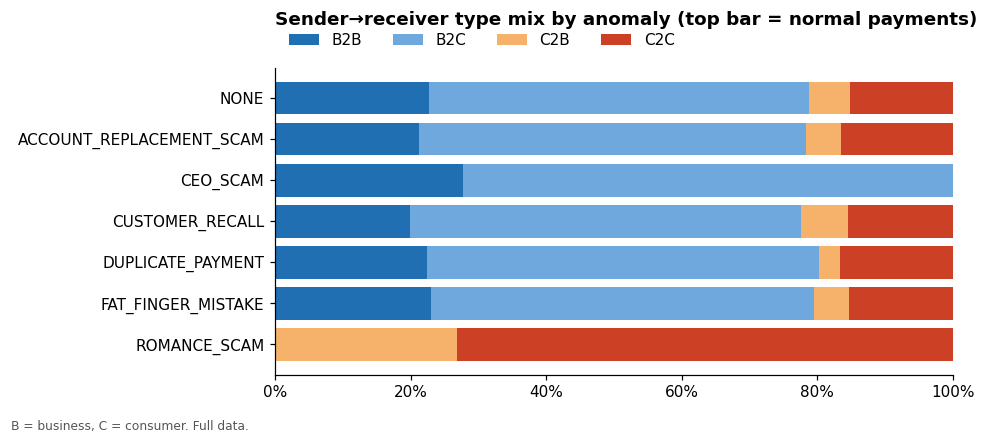

In [33]:
# A-1: sender->receiver pair mix of each anomaly vs normal payments
mix = q("SELECT anomaly, pair, count(*) AS n FROM p GROUP BY ALL")
mix = mix.pivot(index="anomaly", columns="pair", values="n").fillna(0)
mix = mix.div(mix.sum(axis=1), axis=0)
mix = mix.loc[["NONE"] + [i for i in mix.index if i != "NONE"]]
fig, ax = plt.subplots(figsize=(9, 4))
left = np.zeros(len(mix))
for col, colr in zip(mix.columns, ["#1F6FB2", "#6FA8DC", "#F6B26B", "#CC4125"]):
    ax.barh(mix.index, mix[col], left=left, color=colr, label=col); left += mix[col].values
ax.invert_yaxis(); ax.set_xlim(0, 1); ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.legend(ncol=4, bbox_to_anchor=(0, 1.02), loc="lower left", frameon=False)
ax.set_title("Sender→receiver type mix by anomaly (top bar = normal payments)", pad=28)
finish(fig, "A1_pair_mix_by_anomaly", "B = business, C = consumer. Full data.")

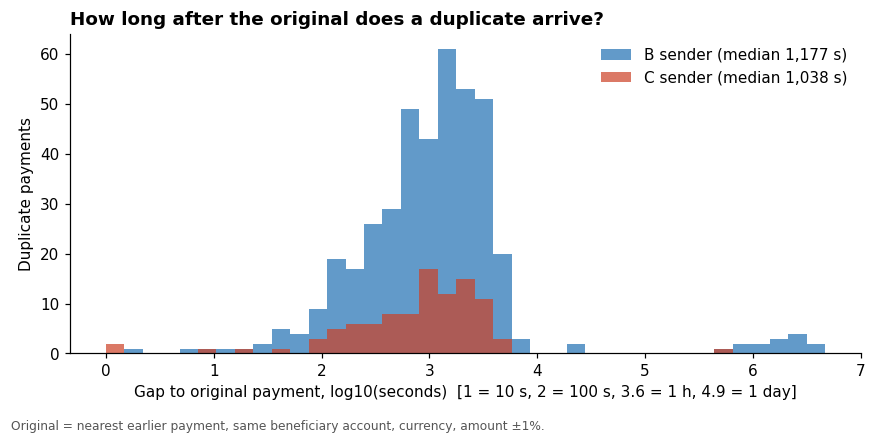

In [34]:
# A-2: duplicate gap distribution by sender type
g = q("SELECT ORDERING_TYPE AS sender_type, gap_s FROM dup_match")
if len(g):
    fig, ax = plt.subplots(figsize=(8, 4))
    bins = np.linspace(0, np.log10(g.gap_s.max() + 1) + 0.1, 40)
    for t, colr in [("B", HI), ("C", "#CC4125")]:
        s = g[g.sender_type == t].gap_s
        if len(s):
            ax.hist(np.log10(s + 1), bins=bins, alpha=.7, color=colr, label=f"{t} sender (median {s.median():,.0f} s)")
    ax.set_xlabel("Gap to original payment, log10(seconds)  [1 = 10 s, 2 = 100 s, 3.6 = 1 h, 4.9 = 1 day]")
    ax.set_ylabel("Duplicate payments"); ax.legend(frameon=False)
    ax.set_title("How long after the original does a duplicate arrive?")
    finish(fig, "A2_duplicate_gap", "Original = nearest earlier payment, same beneficiary account, currency, amount ±1%.")

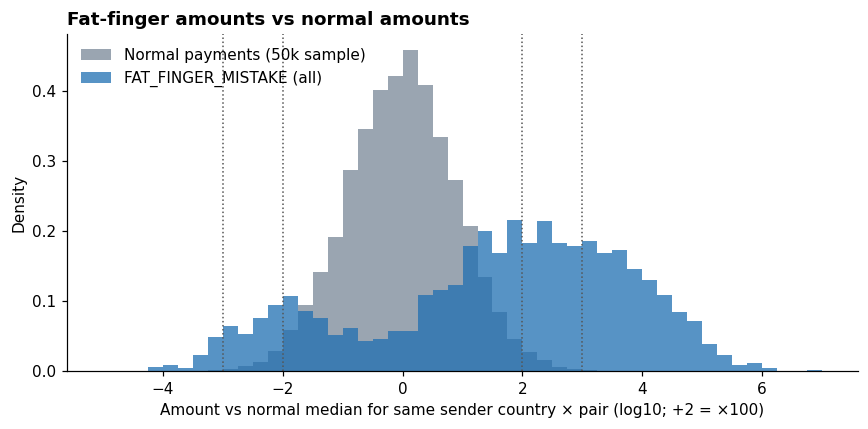

In [35]:
# A-3: fat-finger amount shift vs normal
s = q("""
SELECT anomaly = 'FAT_FINGER_MISTAKE' AS ff, log10(USD_AMOUNT) - b.med_log10 AS sh
FROM (SELECT * FROM p WHERE anomaly = 'FAT_FINGER_MISTAKE'
      UNION ALL SELECT * FROM (SELECT * FROM p WHERE anomaly='NONE') USING SAMPLE reservoir(50000 ROWS) REPEATABLE (42)) x
JOIN amt_base b USING (o_cc, pair) WHERE USD_AMOUNT > 0""")
fig, ax = plt.subplots(figsize=(8, 4))
bins = np.arange(np.floor(s.sh.min()), np.ceil(s.sh.max()) + 0.25, 0.25)
ax.hist(s[~s.ff].sh, bins=bins, density=True, color=BASE, label="Normal payments (50k sample)")
ax.hist(s[s.ff].sh, bins=bins, density=True, color=HI, alpha=.75, label="FAT_FINGER_MISTAKE (all)")
for k in (-3, -2, 2, 3):
    ax.axvline(k, ls=":", c=GREY, lw=1)
ax.set_xlabel("Amount vs normal median for same sender country × pair (log10; +2 = ×100)")
ax.set_ylabel("Density"); ax.legend(frameon=False, loc="upper left")
ax.set_title("Fat-finger amounts vs normal amounts")
finish(fig, "A3_fatfinger_shift")

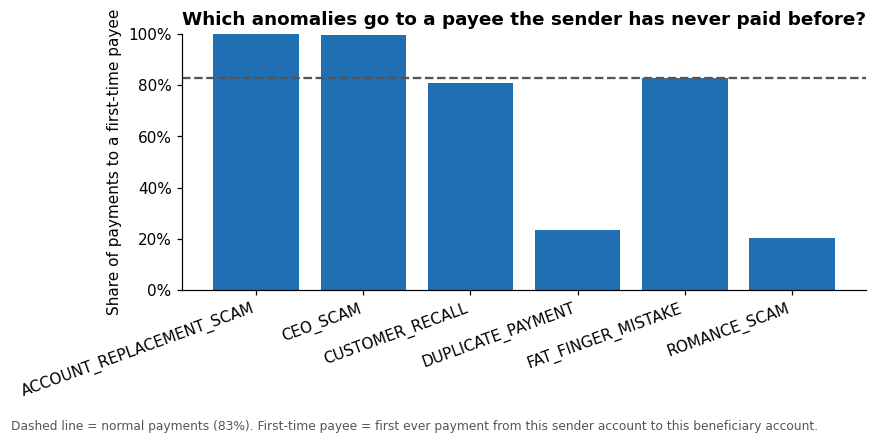

In [36]:
# A-4: first-time payee share by anomaly vs normal (baseline line)
pf = prof.set_index("grp")
base = pf.loc["NONE (all)", "first_time_payee"]
an = pf.drop(index=[i for i in pf.index if i.startswith("NONE")])
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(an.index, an.first_time_payee, color=HI)
ax.axhline(base, ls="--", c=GREY)
ax.set_ylim(0, 1); ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_ylabel("Share of payments to a first-time payee"); plt.xticks(rotation=20, ha="right")
ax.set_title("Which anomalies go to a payee the sender has never paid before?")
finish(fig, "A4_first_time_payee", f"Dashed line = normal payments ({base:.0%}). First-time payee = first ever payment from this sender account to this beneficiary account.")

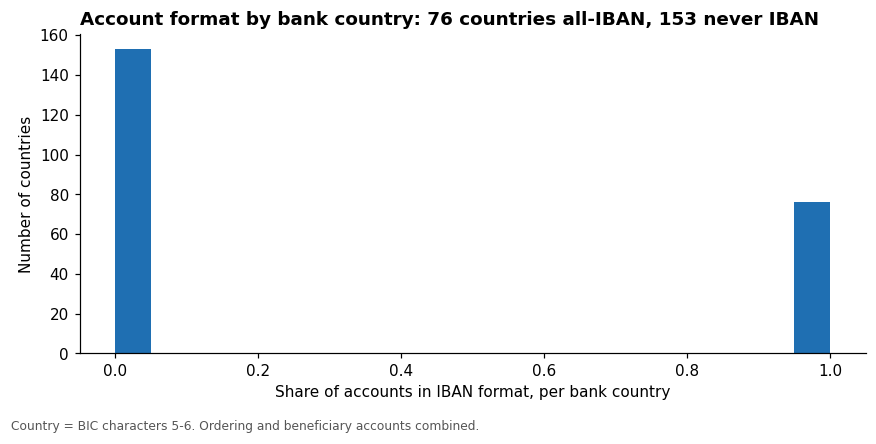

In [37]:
# AC-1: IBAN share per bank country is all-or-nothing?
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(iban_cc.iban_share, bins=20, color=HI)
ax.set_xlabel("Share of accounts in IBAN format, per bank country"); ax.set_ylabel("Number of countries")
ax.set_title(f"Account format by bank country: {(iban_cc.iban_share > .99).sum()} countries all-IBAN, "
             f"{(iban_cc.iban_share < .01).sum()} never IBAN")
finish(fig, "AC1_iban_share_by_country", "Country = BIC characters 5-6. Ordering and beneficiary accounts combined.")

findfont: Font family ['cmsy10'] not found. Falling back to DejaVu Sans.


findfont: Font family ['cmr10'] not found. Falling back to DejaVu Sans.


findfont: Font family ['cmtt10'] not found. Falling back to DejaVu Sans.


findfont: Font family ['cmmi10'] not found. Falling back to DejaVu Sans.


findfont: Font family ['cmb10'] not found. Falling back to DejaVu Sans.


findfont: Font family ['cmss10'] not found. Falling back to DejaVu Sans.


findfont: Font family ['cmex10'] not found. Falling back to DejaVu Sans.


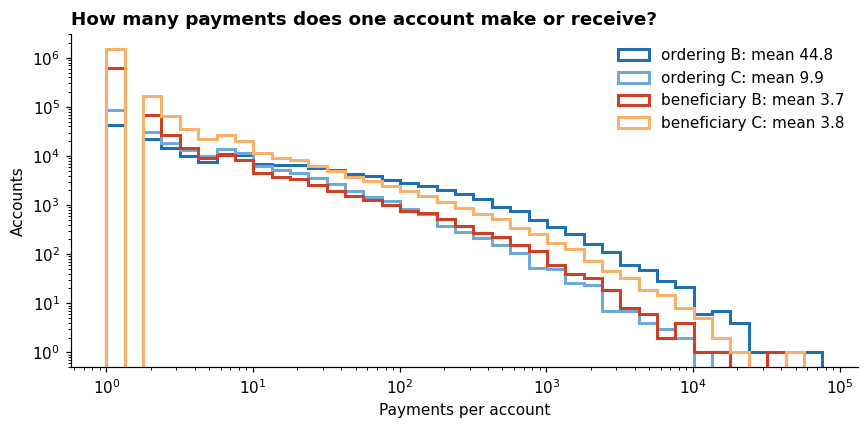

In [38]:
# AC-2: payments per account, by role x party type
acts = q("""SELECT role, typ, n, count(*) AS accounts
            FROM (SELECT role, typ, bic, acct, count(*) AS n FROM acct_long2 GROUP BY ALL) GROUP BY ALL""")
fig, ax = plt.subplots(figsize=(8, 4))
bins = np.logspace(0, np.log10(acts.n.max() + 1), 40)
for (r, t), colr in zip([("ordering", "B"), ("ordering", "C"), ("beneficiary", "B"), ("beneficiary", "C")],
                        [HI, "#6FA8DC", "#CC4125", "#F6B26B"]):
    g = acts[(acts.role == r) & (acts.typ == t)]
    if len(g):
        mean = (g.n * g.accounts).sum() / g.accounts.sum()
        ax.hist(g.n, bins=bins, weights=g.accounts, histtype="step", lw=2, color=colr, label=f"{r} {t}: mean {mean:.1f}")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("Payments per account"); ax.set_ylabel("Accounts")
ax.legend(frameon=False); ax.set_title("How many payments does one account make or receive?")
finish(fig, "AC2_payments_per_account")

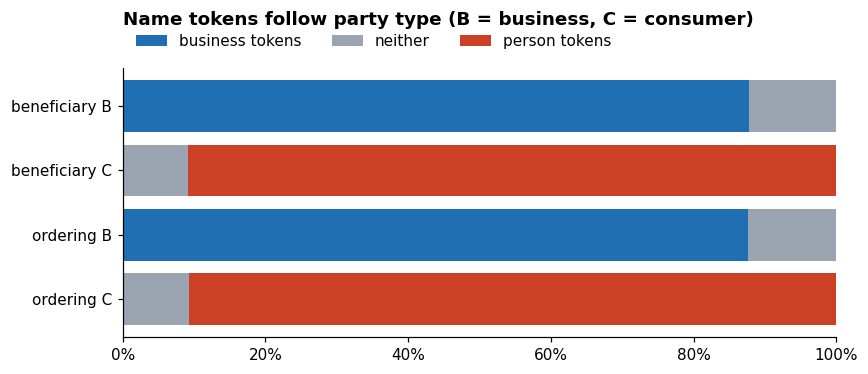

In [39]:
# D-1: name token class vs party type
piv = nc.pivot_table(index=["side", "typ"], columns="name_class", values="share").fillna(0)
fig, ax = plt.subplots(figsize=(8, 3.5))
left = np.zeros(len(piv)); labels = [f"{s} {t}" for s, t in piv.index]
for col, colr in zip(piv.columns, [HI, BASE, "#CC4125"]):
    ax.barh(labels, piv[col], left=left, color=colr, label=col); left += piv[col].values
ax.set_xlim(0, 1); ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}")); ax.invert_yaxis()
ax.legend(ncol=3, bbox_to_anchor=(0, 1.02), loc="lower left", frameon=False)
ax.set_title("Name tokens follow party type (B = business, C = consumer)", pad=28)
finish(fig, "D1_name_tokens_by_party_type")

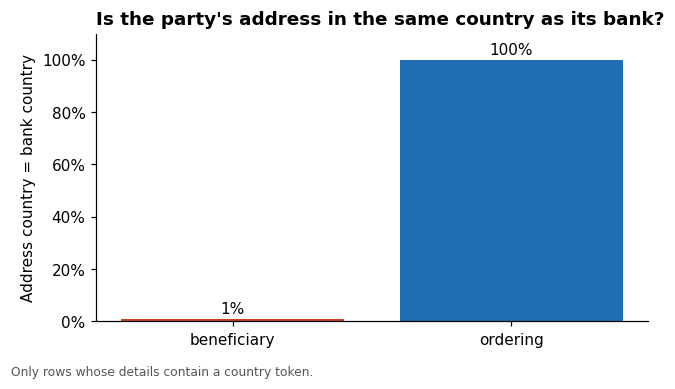

In [40]:
# D-2: address country = bank country, sender vs receiver
dd = det.groupby("side").apply(lambda g: np.average(g.addr_country_eq_bank.fillna(0), weights=g.n * g.has_country), include_groups=False)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(dd.index, dd.values, color=[HI if i == "ordering" else "#CC4125" for i in dd.index])
for i, v in enumerate(dd.values):
    ax.text(i, v + .02, f"{v:.0%}", ha="center")
ax.set_ylim(0, 1.1); ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_ylabel("Address country = bank country")
ax.set_title("Is the party's address in the same country as its bank?")
finish(fig, "D2_address_vs_bank_country", "Only rows whose details contain a country token.")

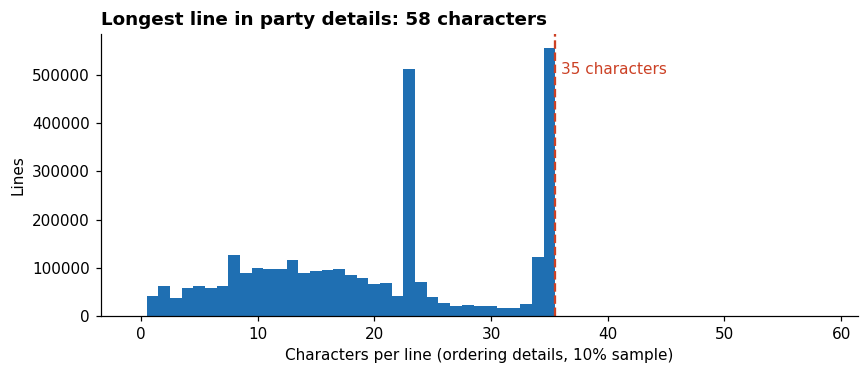

In [41]:
# D-3: line-length ceiling
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(linelen.line_len, linelen.n, color=HI, width=1)
ax.axvline(35.5, ls="--", c="#CC4125"); ax.text(36, linelen.n.max() * .9, "35 characters", color="#CC4125")
ax.set_xlabel("Characters per line (ordering details, 10% sample)"); ax.set_ylabel("Lines")
ax.set_title(f"Longest line in party details: {int(linelen.line_len.max())} characters")
finish(fig, "D3_line_length")

## 8. Rules log
Write one row per rule **after** reading the tables above, in `outputs/tables/rules/rules_03_anomalies.csv`. Use the template: condition → effect → size → scope → exceptions, then observed evidence, real-world interpretation, rejected alternative and confidence (Confirmed / Strong / Partial / Rejected).
`combine_rules()` merges this file with the other notebooks' rules into `outputs/tables/rules_log.csv`.

In [42]:
# Rules log for this notebook: every value below is computed by the cells above (no hand-typed numbers).
# Rows you add by hand to rules_03_anomalies.csv with a NEW id are kept; computed ids are refreshed on every run.
tst = tests.set_index('test')
def t_val(key):
    r = tst.loc[[i for i in tst.index if i.startswith(key)][0]]
    return f"{r.share:.1%} vs {r.control_share:.1%} control (diff {r['diff']:+.1%} [{r.diff_lo:+.1%}, {r.diff_hi:+.1%}], {fmt_p(r.p_z)})"
def best(detector):
    d = detp[detp.detector == detector].sort_values('precision', ascending=False).iloc[0]
    return d, f"exploratory in-sample rule '{d.rule}': precision {d.precision:.1%}, recall {d.recall:.1%}, {d.alerts_per_10k:.1f} alerts per 10k payments; NOT validated for unseen transactions"
def has(key): return any(i.startswith(key) for i in tst.index)
def a1_verdict():
    r = tst.loc[[i for i in tst.index if i.startswith('A1')][0]]
    return 'Confirmed' if r.diff_lo > 0 and r.p_z < 1e-3 else 'Inconclusive'
iban = pd.read_csv(TAB / 'ac_iban_by_country.csv'); cia = pd.read_csv(TAB / 'ac_currency_in_account.csv').iloc[0]
o2o = pd.read_csv(TAB / 'ac_one_to_one.csv').set_index('role'); dpf = pd.read_csv(TAB / 'd_details_profile.csv')
ncl = pd.read_csv(TAB / 'd_name_class_by_type.csv'); chi_ = pd.read_csv(TAB / 'a_chi2_by_segment.csv')
und_ = und.groupby('anomaly').apply(lambda d: pd.Series({'n': d.n.sum(), 'no_link': d.loc[d.direction == 'no link', 'n'].sum()}))
mixed = ((iban.iban_share > 0.01) & (iban.iban_share < 0.99)).sum()
nm = lambda side, typ, cls: ncl.query('side == @side and typ == @typ and name_class == @cls').share.sum()
nb_tot = lambda side, typ: ncl.query('side == @side and typ == @typ').n.sum()
dp_typ = lambda side, typ, col: dpf.query('side == @side and typ == @typ')[col].iloc[0]
money_ = money.set_index('anomaly')
R, E = [], []
def add(rid, grp, rule, test, value, verdict, files, meaning, causal, practical='', stat='', pv='', oos='', inv='', ho=None):
    R.append(dict(id=rid, group=grp, rule=rule, test=test, value=value, verdict=verdict, evidence_files=files, interpretation=meaning))
    E.append(dict(id=rid, statistic_ci=stat or value, p_value=pv, out_of_sample=oos, invariance=inv, causal_status=causal, practical_significance=practical,
                  holdout_agrees=(ho or {}).get('holdout_agrees'), holdout_rule=(ho or {}).get('holdout_rule')))
usd_txt = lambda a: f"{money_.loc[a, 'share_of_usd']:.2%} of all USD value ({money_.loc[a, 'n']:,} payments)" if a in money_.index else '-'

if has('A1'):
    d, txt = best('fat finger')
    add('A1', 'Anomalies', 'Fat-finger-labelled payments are disproportionately extreme in size versus comparable normal payments; an exact x10^k mechanism is not established',
        'share of payments whose rounded log10 distance from the country x pair median is >= 2 (about 32x or more)', t_val('A1'),
        a1_verdict(),  # graded on the rule as worded (size outliers vs control); the exact x10^k multiplier is not claimed
        'a_fatfinger_k_share.csv; a_significance_tests.csv; a_detector_performance.csv; a_out_of_sample_and_by_month.csv', 'Consistent with a keying slip that multiplies the amount by a power of 10',
        'Association', practical=f"{usd_txt('FAT_FINGER_MISTAKE')}; retrospective detector: {txt}", oos=A_EV['A1']['oos'], inv=A_EV['A1']['inv'], ho=A_EV['A1'])
if has('A2'):
    d, txt = best('duplicate')
    add('A2', 'Anomalies', f'Duplicates come in bursts of {int(burst.kmin)}-{int(burst.kmax)} identical payments (same sender, payee, currency and amount) '
        f'about {burst.med_gap / 60:.0f} minutes apart; every copy in these bursts is labelled, and an earlier unlabelled match is '
        + ('found no more often than by chance (no evidence of unlabelled originals)' if burst.first_with_orig / burst.bursts <= 2 * burst_ctl else f'found for {burst.first_with_orig / burst.bursts:.0%} of bursts'),
        'burst structure of labelled duplicates; share with an earlier matching payment vs normal payments',
        f"{int(burst.bursts)} bursts of {int(burst.kmin)}-{int(burst.kmax)} copies, identical amount {burst.exact_amount:.0%}, median {burst.med_gap:.0f}s apart; "
        f"first copy with an earlier unlabelled match {burst.first_with_orig / burst.bursts:.1%} (normal {burst_ctl:.1%}); earlier match (any copy): "
        + '; '.join(t_val(f'A2 earlier same-payee/amount payment, sender {s}') for s in 'BC' if has(f'A2 earlier same-payee/amount payment, sender {s}')),
        'Strong', 'a_duplicate_bursts.csv; a_duplicates_vs_control.csv; a_significance_tests.csv; a_detector_performance.csv; a_out_of_sample_and_by_month.csv', 'Consistent with a back-office re-submission of the same instruction',
        'Mechanism' if d.precision >= 0.5 else 'Association', practical=f"{usd_txt('DUPLICATE_PAYMENT')} paid twice; detector: {txt}", oos=A_EV['A2']['oos'], inv=A_EV['A2']['inv'], ho=A_EV['A2'])
if A2B.n.notna().all() and A2B.n.min() >= 5:
    same_ok = (A2B.same / A2B.n >= 0.9).all(); gap_ok = (A2B.med_gap < 3600).all()
    te_ok = A2B_te.n.notna().all() and A2B_te.n.min() >= 5 and (A2B_te.same / A2B_te.n >= 0.9).all() and (A2B_te.med_gap < 3600).all()
    add('A2b', 'Anomalies', 'Business and consumer duplicates follow the same pattern: re-sent by the same sender, minutes later. '
        'The hypothesised consumer pattern (a different sender, hours or days later) is not found',
        'same-sender share and gap to the matched original, by sender type (duplicates with a match)',
        f"same sender: B {share_ci(A2B.loc['B', 'same'], A2B.loc['B', 'n'], 1)}, C {share_ci(A2B.loc['C', 'same'], A2B.loc['C', 'n'], 1)}; "
        f"median gap B {A2B.loc['B', 'med_gap']:.0f}s, C {A2B.loc['C', 'med_gap']:.0f}s (Mann-Whitney {fmt_p(A2B_mw)})",
        'Confirmed' if same_ok and gap_ok else 'Partial', 'a_duplicates_b_vs_c.csv; a_duplicates_vs_control.csv',
        'One re-submission pattern for both sender types; the B/C split in hypothesis A2 is not supported', 'Association',
        practical='one duplicate rule (same sender, payee and amount, within an hour) covers business and consumer senders alike',
        oos=f"test period: same sender B {A2B_te.loc['B', 'same'] / A2B_te.loc['B', 'n']:.1%}, C {A2B_te.loc['C', 'same'] / A2B_te.loc['C', 'n']:.1%}; "
            f"median gap B {A2B_te.loc['B', 'med_gap']:.0f}s, C {A2B_te.loc['C', 'med_gap']:.0f}s" if A2B_te.n.notna().all() else '',
        ho=holdout(te_ok, 'test period: both sender types >= 90% same sender and median gap under 1 hour'))
if has('A3'):
    d, txt = best('romance')
    add('A3', 'Anomalies', 'Romance scam: one consumer pays the same consumer several times within a day, with rising amounts',
        'C2C pairs with 3+ payments: rising amounts and within-1-day share vs normal pairs', t_val('A3 amounts') + '; within 1 day ' + t_val('A3 all'),
        'Confirmed', 'a_romance_vs_control.csv; a_significance_tests.csv; a_detector_performance.csv; a_out_of_sample_and_by_month.csv', 'Consistent with a victim being groomed into sending more and more',
        'Mechanism' if d.precision >= 0.5 else 'Association', practical=f"{usd_txt('ROMANCE_SCAM')}; detector: {txt}", oos=A_EV['A3']['oos'], inv=A_EV['A3']['inv'], ho=A_EV['A3'])
if has('A4'):
    d, txt = best('CEO')
    add('A4', 'Anomalies', 'CEO scam: business sender, first payment to a new payee, amount above the usual level',
        'first-time payee share vs normal business payments; amount shift (Mann-Whitney)', t_val('A4') + f"; amount shift median {ceo_sh.median():+.2f} log10 vs {ceo_ref.median():+.2f} ({fmt_p(ceo_mw)})",
        'Strong', 'a_profile_vs_control.csv; a_significance_tests.csv; a_detector_performance.csv; a_out_of_sample_and_by_month.csv', 'Consistent with a fake executive ordering an urgent transfer to a new supplier account',
        'Association' if d.precision < 0.5 else 'Mechanism', practical=f"{usd_txt('CEO_SCAM')}; detector: {txt}", oos=A_EV['A4']['oos'], inv=A_EV['A4']['inv'], ho=A_EV['A4'])
nmx = name_matches.iloc[0]
nz = lambda x: 0 if pd.isna(x) else int(x)
k_rel, n_rel = nz(nmx.suspects_with_earlier_name_match), nz(nmx.eligible_suspects)
relaxed = k_rel / n_rel if n_rel else np.nan
a5_linked = pd.notna(relaxed) and relaxed >= 0.05
add('A5', 'Anomalies', 'Account-replacement scams reuse an earlier payee name with a new account (name-level link only)' if a5_linked
    else 'Account-replacement scams: no earlier payment from the same sender to the same payee was found (exact party text, or first name line); '
         'the replacement mechanism is not recovered with these matching methods',
    'earlier payment from the same sender (BIC8 + account) to the same payee: exact party text, then relaxed first-line name match (4.6b); '
    'the same exact-text match finds a predecessor for normal payments, so the method can find links',
    t_val('A5') + f"; relaxed name match {share_ci(k_rel, n_rel, 1)}, with a changed account {nz(nmx.suspects_with_changed_account)}",
    'Partial (name-level link only)' if a5_linked else 'Inconclusive (not recovered with tested matching)',
    'a_account_replacement_vs_control.csv; a_account_replacement_name_diagnostic.csv',
    'Invoice interception would re-use a known payee; check the matched cases by hand before claiming it' if a5_linked
    else 'The label is not tied to a payee history that these joins can see; names or details may be re-generated, so absence of a match does not prove absence of a link',
    'Association' if a5_linked else 'Unresolved', practical=usd_txt('ACCOUNT_REPLACEMENT_SCAM'))
if len(und_):
    add('A6', 'Anomalies', 'For labels outside the appendix (CUSTOMER_RECALL), no linked payment (same sender and receiver bank + account, amount +-1%) was found for almost all rows',
        'share of these rows with no matching payment (observation only)',
        '; '.join(f'{a}: {share_ci(r.no_link, r.n, 1)}' for a, r in und_.iterrows()), 'Confirmed' if (und_.no_link / und_.n).min() >= 0.95 else 'Partial',
        'a_undocumented_label_links.csv; qc_issues_log.csv',
        'Observation only: how recalls arise is unresolved (the label is not defined in the appendix; ask the organisers)', 'Unresolved',
        practical=usd_txt('CUSTOMER_RECALL') + ' carry a label the appendix does not define: kept and reported separately')
sig = chi_[chi_.chi2_p < 0.001]
seg_sig = sorted(set(sig.segment_var)); seg_all = sorted(set(chi_.segment_var))
add('A7', 'Anomalies', 'Anomaly rates are not uniform: they differ by ' + (', '.join(seg_sig) if seg_sig else 'no segment')
    + (f"; no difference by {', '.join(s_ for s_ in seg_all if s_ not in seg_sig)}" if set(seg_all) - set(seg_sig) else ''),
    'chi-square per anomaly x segment (p < 0.001 counted)', f'{len(sig)} of {len(chi_)} anomaly x segment tests significant: ' + ', '.join(seg_sig),
    'Partial', 'a_chi2_by_segment.csv; a_lift_by_segment.csv', 'Each scam type concentrates in its own segments; the cause is not identified', 'Association',
    stat=f'{len(sig)} of {len(chi_)} tests with p < 0.001 (largest lift in a_lift_by_segment.csv)',
    practical='alert thresholds should be set per segment (e.g. per B/C pair), not one global rate')
add('AC1', 'Accounts', 'IBAN is used for every account of a bank country or for none; IBAN country = BIC country', 'countries with mixed formats; IBAN country match',
    f"{(iban.iban_share >= 0.99).sum()} countries all-IBAN, {(iban.iban_share <= 0.01).sum()} none, {mixed} mixed; country match {np.average(iban[iban.iban_share >= 0.99].iban_cc_match, weights=iban[iban.iban_share >= 0.99].n):.2%}",
    'Confirmed' if mixed == 0 else 'Strong', 'ac_iban_by_country.csv', 'IBAN is a national standard, adopted country by country', 'Structural')
add('AC2', 'Accounts', "Non-IBAN account numbers that contain a currency code use the bank country's local currency", 'share of non-IBAN accounts with a 3-letter code; match',
    f"{cia.has_3letter_code:.1%} contain a code; {cia.code_equals_local_ccy:.1%} of those = local currency", verdict_from_share(cia.code_equals_local_ccy),
    'ac_currency_in_account.csv', 'Domestic account numbers often carry the account currency', 'Structural')
add('AC3', 'Accounts', f"Each sender account number belongs to one bank and one party type; {o2o.loc['beneficiary', 'multi_bic']:.1%} of receiver account numbers recur under several banks, so every account history uses (BIC8, account)", 'share of account numbers with > 1 BIC / party type',
    f"multi-BIC: sender {o2o.loc['ordering', 'multi_bic']:.2%}, receiver {o2o.loc['beneficiary', 'multi_bic']:.2%}; multi-type {max(o2o.multi_party_type):.2%}",
    verdict_from_share(1 - o2o.multi_bic.max()), 'ac_one_to_one.csv', 'Account numbers are issued per bank, so the same number can exist at two banks', 'Structural')
add('D1', 'Details', 'Party details lines are at most 35 characters (SWIFT MT line format)', 'share of details texts with every line <= 35 characters',
    f"{dpf.all_lines_le_35.min():.2%}-{dpf.all_lines_le_35.max():.2%} by side x type", verdict_from_share(dpf.all_lines_le_35.min()), 'd_details_profile.csv',
    'The 4 x 35 character field of SWIFT MT messages', 'Structural')
add('D3', 'Details', 'Business parties get company-name tokens; consumers get person-name tokens', 'share by party type',
    f"receiver B business {nm('beneficiary', 'B', 'business tokens'):.1%}; receiver C person {nm('beneficiary', 'C', 'person tokens'):.1%}",
    verdict_from_share(min(nm('beneficiary', 'B', 'business tokens'), nm('beneficiary', 'C', 'person tokens'))), 'd_name_class_by_type.csv',
    'Consistent with a name generator that depends on the party type', 'Mechanism',
    stat=f"receiver B business {share_ci(nm('beneficiary', 'B', 'business tokens') * nb_tot('beneficiary', 'B'), nb_tot('beneficiary', 'B'), 1)}; "
         f"receiver C person {share_ci(nm('beneficiary', 'C', 'person tokens') * nb_tot('beneficiary', 'C'), nb_tot('beneficiary', 'C'), 1)}",
    oos=A_EV['D3']['oos'], inv=A_EV['D3']['inv'], ho=A_EV['D3'], practical='the details text identifies the party type in about 9 of 10 payments: a B/C label that disagrees with the name is worth a check')
add('D4', 'Details', "Sender address country = sender bank country; the receiver's address country usually differs", 'share of address country = bank country',
    f"sender {dpf[dpf.side == 'ordering'].addr_country_eq_bank.mean():.1%}; receiver {dpf[dpf.side == 'beneficiary'].addr_country_eq_bank.mean():.1%}",
    verdict_from_share(dpf[dpf.side == 'ordering'].addr_country_eq_bank.min()), 'd_details_profile.csv', 'Consistent with senders banking locally while receivers can live anywhere', 'Association',
    oos=A_EV['D4']['oos'], inv=A_EV['D4']['inv'], ho=A_EV['D4'], practical="a sender address abroad is unusual and worth a check; a receiver's address says little about the receiving bank")
# D2: are the three details formats mutually exclusive?
d2 = q(r"""WITH x AS (SELECT 'ordering' side, replace(ORDERING_DETAILS, chr(13), '') det FROM p
                     UNION ALL SELECT 'beneficiary', replace(BENEFICIARY_DETAILS, chr(13), '') FROM p),
         y AS (SELECT side, regexp_matches(det, '(^|\n)1/') s, regexp_matches(det, '(^|\n)[0-9]{4}[A-Z]{2}[A-Z0-9]{2}\s*$') b FROM x)
         SELECT side, count(*) n, sum((s AND NOT b)::INT) structured, sum((b AND NOT s)::INT) bic_only,
                sum((NOT s AND NOT b)::INT) free_text, sum((s AND b)::INT) both_formats FROM y GROUP BY 1""").set_index('side')
save(d2.reset_index(), 'd_details_formats')
d2n = d2.n.sum(); d2_both = d2.both_formats.sum()
d2_free = d2.free_text.sum() / d2n
add('D2', 'Details', f'The numbered (1/2/3/ lines) and BIC-line formats never occur in the same details text; the other {d2_free:.0%} match neither '
    '(free text: a residual class, not a tested third template)',
    'share of details texts matching BOTH explicit formats (the rule predicts 0), both sides, full data',
    '; '.join(f"{sd}: numbered {r.structured / r.n:.1%}, BIC line {r.bic_only / r.n:.1%}, neither (free text) {r.free_text / r.n:.1%}, both {r.both_formats / r.n:.3%}" for sd, r in d2.sort_index().iterrows()),
    verdict_from_share(1 - d2_both / d2n), 'd_details_formats.csv; d_details_profile.csv',
    'Consistent with one format being chosen per party text; regex classes describe the text and do not show how the free text is generated', 'Association',
    stat=f'texts matching both formats: {share_ci(d2_both, d2n, 3)}',
    practical=f'a details parser can branch on the format (numbered fields or a trailing BIC line, never both); the {d2_free:.0%} free text needs name/address parsing')
# D5: is the trailing finance/stop-word line random filler (same rate for anomalies as for normal payments)?
pr5 = prof.set_index('grp'); base5 = pr5.loc['NONE (all)']
d5 = [(g, side, *two_prop(round(r[col] * r.n), r.n, round(base5[col] * base5.n), base5.n)) for g, r in pr5.iterrows()
      if g not in ('NONE (all)', 'NONE, B sender', 'NONE, C sender') and r.n >= 300 for side, col in [('sender', 'noise_line_o'), ('receiver', 'noise_line_b')]]
d5 = pd.DataFrame(d5, columns=['group', 'side', 'diff', 'ci', 'p'])
save(d5.assign(ci_lo=d5.ci.str[0], ci_hi=d5.ci.str[1]).drop(columns='ci'), 'd_noise_line_vs_normal')
d5_max = d5['diff'].abs().max(); d5_sig = int((d5.p < 0.001).sum())
add('D5', 'Details', 'No detectable difference in the trailing finance / stop-word line rate between any anomaly type and normal payments (gaps of up to about 3 points cannot be excluded)',
    'difference in the share with a filler line, each anomaly type vs all normal payments (two-proportion z-test)',
    (f'largest difference {d5_max * 100:.1f} points; {d5_sig} of {len(d5)} comparisons with p < 0.001, {int((d5.p < 0.05).sum())} with p < 0.05' if len(d5) else 'too few anomaly rows (< 300 per type) to compare'),
    'Confirmed' if d5_max < 0.01 and d5_sig == 0 else 'Partial', 'd_noise_line_vs_normal.csv; a_profile_vs_control.csv',
    'Consistent with filler text that carries no anomaly information; this does not show how the filler is generated or that it is random', 'Association',
    practical='the filler line cannot be used to detect anomalies')

rules_path = RULES / 'rules_03_anomalies.csv'
new = pd.DataFrame(R, columns=RULE_COLS)
if rules_path.exists():                     # keep hand-written rows with their own ids (drops the old template row)
    old = pd.read_csv(rules_path)
    keep = old[~old.id.isin(new.id) & ~old.id.astype(str).str.endswith('-example')]
    if len(keep): print('kept hand-written rules:', keep.id.tolist())
    if len(keep): new = pd.concat([new, keep], ignore_index=True)
new = new[[c for c in new.columns if c in RULE_COLS or new[c].notna().any()]]     # drop empty columns left by the old template
new.to_csv(rules_path, index=False)
save_evidence(E, '03')
display(new[['id', 'group', 'value', 'verdict']])

# Fill the hypothesis table's status from the computed rules, so no stale 'TODO' is left
# Statuses describe the HYPOTHESIS as written (which can differ from the rule that was finally tested)
stat = new.set_index('id').verdict.to_dict()
und_n, und_k = (int(und_.n.sum()), int(und_.no_link.sum())) if len(und_) else (0, 0)
HYP_STATUS = {
    'A1': f"Partly: fat-finger payments are far more often about 32x or more away from the typical amount (rounded order of magnitude >= 2; test grade {stat.get('A1', '-')}); "
          "an exact x10^k multiplier is not established",
    'D2': f"Partly: the numbered and BIC-line formats never occur together (test grade {stat.get('D2', '-')}); "
          "the free text is a residual class, not a tested third template",
    'A2': (f"Re-send pattern (test grade {stat.get('A2', '-')}); the B (seconds) vs C (other sender, hours/days) split is NOT supported: "
           f"both re-sent by the same sender minutes later (rule A2b, test grade {stat.get('A2b', '-')})") if 'A2b' in stat else
          f"Re-send pattern (test grade {stat.get('A2', '-')}); the B vs C split could not be tested (too few matched duplicates)",
    'A5': stat.get('A5', '-'),
    'A6': f"Not supported: {und_k} of {und_n} undocumented-label rows have no linked payment (rule A6 reports the observation)",
    'A7': f"Null rejected for {', '.join(seg_sig) or 'none'}" + (f"; not rejected for {', '.join(x for x in seg_all if x not in seg_sig)}" if set(seg_all) - set(seg_sig) else ''),
}
hyp = pd.read_csv(hyp_path)
hyp['status'] = [HYP_STATUS.get(i, f'test grade {stat[i]}' if i in stat else 'Not tested: excluded from rule claims') for i in hyp.id]
# 'test grade' = notebook 03's own grade; notebook 04 adds the final verdict (single verdict system) as final_verdict
hyp['evidence'] = hyp.id.map(new.set_index('id').evidence_files.to_dict()).fillna('-')
hyp.to_csv(hyp_path, index=False); display(hyp[['id', 'hypothesis', 'status']])
combine_rules();

,id,group,value,verdict
0,A1,Anomalies,"72.0% vs 9.7% control (diff +62.3% [+60.3%, +6...",Confirmed
1,A2,Anomalies,"185 bursts of 2-5 copies, identical amount 100...",Strong
2,A2b,Anomalies,"same sender: B 96.6% [94.4%, 98.0%], n = 412, ...",Confirmed
3,A3,Anomalies,"98.8% vs 50.4% control (diff +48.3% [+47.0%, +...",Confirmed
4,A4,Anomalies,"99.8% vs 81.3% control (diff +18.5% [+18.2%, +...",Strong
5,A5,Anomalies,"0.0% vs 5.7% control (diff -5.7% [-6.4%, -5.1%...",Inconclusive (not recovered with tested matching)
6,A6,Anomalies,"CUSTOMER_RECALL: 99.1% [97.3%, 99.7%], n = 317",Confirmed
7,A7,Anomalies,14 of 42 anomaly x segment tests significant: ...,Partial
8,AC1,Accounts,"76 countries all-IBAN, 153 none, 0 mixed; coun...",Confirmed
9,AC2,Accounts,13.3% contain a code; 99.6% of those = local c...,Confirmed


,id,hypothesis,status
0,A1,FAT_FINGER amount = normal amount x 10^k (k = ...,Partly: fat-finger payments are far more often...
1,A2,DUPLICATE: B = same sender seconds apart; C = ...,Re-send pattern (test grade Strong); the B (se...
2,A3,"ROMANCE: C2C, same pair repeats, amounts rise ...",test grade Confirmed
3,A4,"CEO_SCAM: B sender, above-normal amount, first...",test grade Strong
4,A5,ACCOUNT_REPLACEMENT: same payee name as before...,Inconclusive (not recovered with tested matching)
5,A6,Undocumented label links back to an earlier pa...,Not supported: 314 of 317 undocumented-label r...
6,A7,Null: anomaly rate is flat across pair / type ...,"Null rejected for conversions, cross_border, h..."
7,AC1,IBAN format <=> bank country uses IBAN; IBAN c...,test grade Confirmed
8,AC2,Non-IBAN accounts embed the bank country's cur...,test grade Confirmed
9,AC3,Each account belongs to exactly one BIC and on...,test grade Strong
